In [1]:
%pip install opencv-python-headless scikit-image pandas tqdm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path
import os
import time
import cv2
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from skimage.metrics import structural_similarity

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

# Use the manifests from your GOES-19 patch dataset
TRAIN_CSV = Path(
    PROJECT_DIR
) / "Dataset/GOES_TrainPatches_2048_NEW/train_patches.csv"

TEST_CSV = Path(
    PROJECT_DIR
) / "Dataset/GOES_TestPatches_2048/test_patches.csv"

OUTPUT_DIR = Path(PROJECT_DIR) / "results/simple_baselines"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Training patches:", len(train_df))
print("Testing patches:", len(test_df))
print("Train columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())

Training patches: 5067
Testing patches: 1265
Train columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']
Test columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']


In [3]:
def load_array(path):
    path = str(path)

    if path.endswith(".npy"):
        arr = np.load(path, allow_pickle=False)

    elif path.endswith(".npz"):
        with np.load(path, allow_pickle=False) as data:
            # Use the first stored array
            arr = data[data.files[0]]

    else:
        raise ValueError(f"Unsupported file format: {path}")

    arr = np.asarray(arr).squeeze()

    if arr.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale patch, got {arr.shape}: {path}"
        )

    return arr.astype(np.float32)


def load_triplet(row):
    img0 = load_array(row["img0_path"])
    gt = load_array(row["gt_path"])
    img2 = load_array(row["img2_path"])

    if not (img0.shape == gt.shape == img2.shape):
        raise ValueError(
            f"Image dimensions differ: {img0.shape}, "
            f"{gt.shape}, {img2.shape}"
        )

    if "mask_gt_path" in row.index and pd.notna(row["mask_gt_path"]):
        mask = load_array(row["mask_gt_path"]) > 0
    else:
        mask = np.isfinite(gt)

    mask &= np.isfinite(img0) & np.isfinite(img2) & np.isfinite(gt)

    return (
        np.nan_to_num(img0, nan=0.0),
        np.nan_to_num(gt, nan=0.0),
        np.nan_to_num(img2, nan=0.0),
        mask
    )


# Verify one patch before processing the entire dataset
img0, gt, img2, mask = load_triplet(train_df.iloc[0])

print("Input frame:", img0.shape)
print("Ground truth:", gt.shape)
print("Second frame:", img2.shape)
print("Valid GT pixels:", int(mask.sum()))
print("Input range:", img0.min(), img0.max())

Input frame: (2048, 2048)
Ground truth: (2048, 2048)
Second frame: (2048, 2048)
Valid GT pixels: 3988951
Input range: 0.0 0.85839844


In [4]:
def predict_persistence(img0, img2):
    return img0.copy()


def predict_linear(img0, img2):
    return 0.5 * img0 + 0.5 * img2


def predict_optical_flow(img0, img2):
    """
    Farneback optical flow from img0 to img2 and img2 to img0.
    Warp both frames toward the temporal midpoint, then blend.
    """

    # Optical flow works on single-channel images
    frame0 = np.clip(img0 * 255.0, 0, 255).astype(np.uint8)
    frame2 = np.clip(img2 * 255.0, 0, 255).astype(np.uint8)

    # Forward and backward flow fields
    flow_02 = cv2.calcOpticalFlowFarneback(
        frame0, frame2, None,
        pyr_scale=0.5,
        levels=3,
        winsize=15,
        iterations=3,
        poly_n=5,
        poly_sigma=1.2,
        flags=0
    )

    flow_20 = cv2.calcOpticalFlowFarneback(
        frame2, frame0, None,
        pyr_scale=0.5,
        levels=3,
        winsize=15,
        iterations=3,
        poly_n=5,
        poly_sigma=1.2,
        flags=0
    )

    h, w = img0.shape
    xx, yy = np.meshgrid(
        np.arange(w, dtype=np.float32),
        np.arange(h, dtype=np.float32)
    )

    # Approximate midpoint backward-warp coordinates
    map0_x = xx - 0.5 * flow_02[..., 0]
    map0_y = yy - 0.5 * flow_02[..., 1]

    map2_x = xx - 0.5 * flow_20[..., 0]
    map2_y = yy - 0.5 * flow_20[..., 1]

    warped0 = cv2.remap(
        img0, map0_x, map0_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    warped2 = cv2.remap(
        img2, map2_x, map2_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    return 0.5 * warped0 + 0.5 * warped2

In [5]:
def calculate_metrics(pred, gt, mask):
    valid = (
        mask
        & np.isfinite(pred)
        & np.isfinite(gt)
    )

    if valid.sum() == 0:
        return {
            "MSE": np.nan,
            "PSNR_dB": np.nan,
            "SSIM": np.nan,
            "MAE": np.nan,
            "RMSE": np.nan,
            "FSIM": np.nan,
            "ValidPixels": 0
        }

    p = pred[valid].astype(np.float64)
    g = gt[valid].astype(np.float64)

    mse = np.mean((p - g) ** 2)
    mae = np.mean(np.abs(p - g))
    rmse = np.sqrt(mse)

    if mse == 0:
        psnr = float("inf")
    else:
        # Images are normalized to [0, 1]
        psnr = 10.0 * np.log10(1.0 / mse)

    # SSIM needs an image rather than a flattened vector.
    # Invalid pixels are filled with GT before SSIM computation.
    pred_filled = np.where(valid, pred, gt)
    gt_filled = np.where(valid, gt, gt)

    ssim_map = structural_similarity(
        gt_filled,
        pred_filled,
        data_range=1.0,
        full=True
    )[1]

    ssim = float(np.mean(ssim_map[valid]))

    return {
        "MSE": float(mse),
        "PSNR_dB": float(psnr),
        "SSIM": ssim,
        "MAE": float(mae),
        "RMSE": float(rmse),
        "FSIM": np.nan,
        "ValidPixels": int(valid.sum())
    }

In [6]:
BASELINES = {
    "Persistence": predict_persistence,
    "LinearInterpolation": predict_linear,
    "FarnebackOpticalFlow": predict_optical_flow,
}


def evaluate_manifest(df, split_name):
    all_results = []

    for method_name, predictor in BASELINES.items():
        print(f"\n{split_name}: {method_name}")

        for idx, (_, row) in enumerate(
            tqdm(df.iterrows(), total=len(df))
        ):
            img0, gt, img2, mask = load_triplet(row)

            start = time.time()
            pred = predictor(img0, img2)
            elapsed = time.time() - start

            metrics = calculate_metrics(pred, gt, mask)

            all_results.append({
                "Split": split_name,
                "Method": method_name,
                "PatchIndex": idx,
                "PatchID": row.get("patch_id", idx),
                "InferenceSeconds": elapsed,
                **metrics
            })

    return pd.DataFrame(all_results)


# Run the test set first
test_results = evaluate_manifest(test_df, "Test")

test_results.to_csv(
    OUTPUT_DIR / "baseline_test_patch_metrics.csv",
    index=False
)

print("Saved test patch metrics.")


Test: Persistence


  0%|          | 0/1265 [00:00<?, ?it/s]


Test: LinearInterpolation


  0%|          | 0/1265 [00:00<?, ?it/s]


Test: FarnebackOpticalFlow


  0%|          | 0/1265 [00:00<?, ?it/s]

Saved test patch metrics.


In [12]:
metric_cols = [
    "MSE",
    "PSNR_dB",
    "SSIM",
    "MAE",
    "RMSE",
    "FSIM",
    "InferenceSeconds"
]

test_summary = (
    test_results
    .groupby("Method")[metric_cols]
    .mean()
    .reset_index()
)

#train_summary = (
    #train_results
    #.groupby("Method")[metric_cols]
    #.mean()
    #.reset_index()
#)

print("\n===== TEST BASELINE RESULTS =====")
display(test_summary.round(6))

#print("\n===== TRAIN BASELINE RESULTS =====")
#display(train_summary.round(6))

test_summary.to_csv(
    OUTPUT_DIR / "baseline_test_summary.csv",
    index=False
)

#train_summary.to_csv(
    #OUTPUT_DIR / "baseline_train_summary.csv",
    #index=False
#)


===== TEST BASELINE RESULTS =====


,Method,MSE,PSNR_dB,SSIM,MAE,RMSE,FSIM,InferenceSeconds
0,FarnebackOpticalFlow,0.000175,37.787504,0.955988,0.006332,0.013059,NaN,2.670989
1,LinearInterpolation,0.000699,31.998028,0.876658,0.011828,0.025788,NaN,0.007262
2,Persistence,0.001312,29.142318,0.836546,0.016564,0.035572,NaN,0.001428


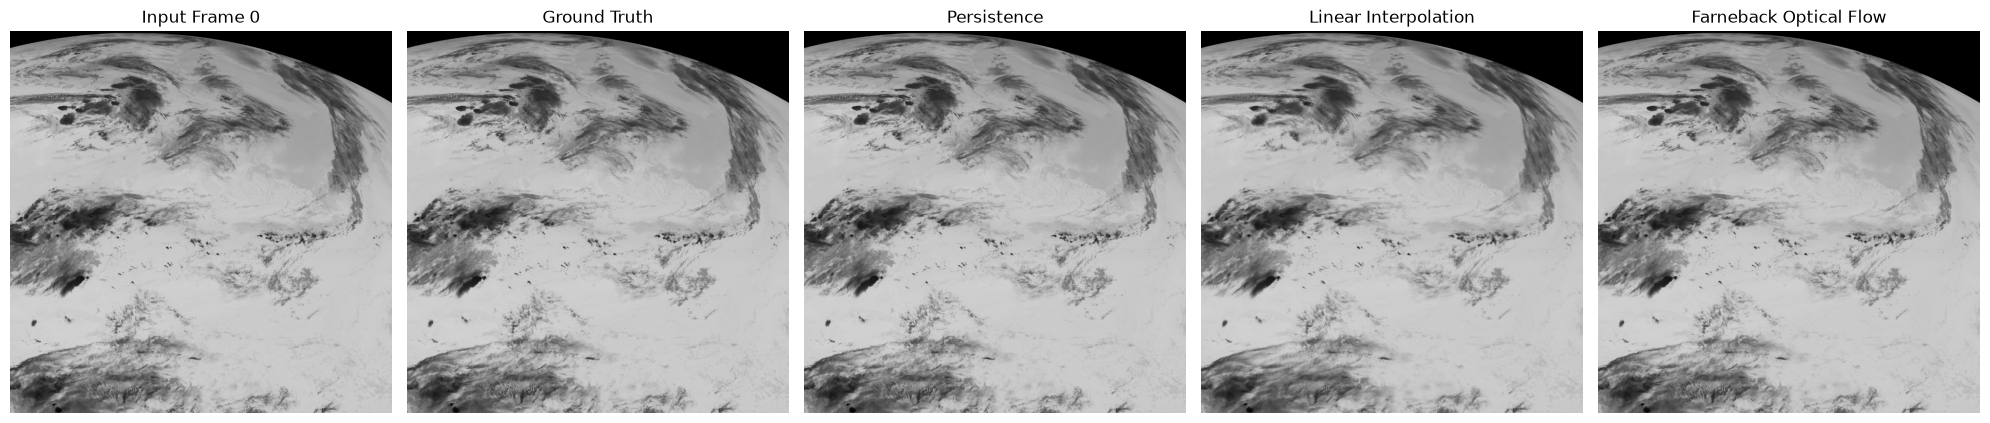

Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/simple_baselines/baseline_visual_comparison.png


In [13]:
import matplotlib.pyplot as plt

row = test_df.iloc[0]
img0, gt, img2, mask = load_triplet(row)

predictions = {
    "Input Frame 0": img0,
    "Ground Truth": gt,
    "Persistence": predict_persistence(img0, img2),
    "Linear Interpolation": predict_linear(img0, img2),
    "Farneback Optical Flow": predict_optical_flow(img0, img2),
}

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (title, image_data) in zip(axes, predictions.items()):
    ax.imshow(image_data, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()

save_path = OUTPUT_DIR / "baseline_visual_comparison.png"
plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

In [1]:
%pip install numpy pandas matplotlib opencv-python-headless scikit-image

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install piq

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:

# ============================================================
# STEP 3: COMMON SETUP FOR GOES-19 TEST PATCHES
# ============================================================

from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity
)

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TEST_CSV = (
    PROJECT_DIR
    / "Dataset"
    / "GOES_TestPatches_2048"
    / "test_patches.csv"
)

OUTPUT_DIR = PROJECT_DIR / "results_NEW" / "simple_baselines"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Test CSV:", TEST_CSV)
print("Output:", OUTPUT_DIR)

if not TEST_CSV.exists():
    raise FileNotFoundError(
        f"Test CSV not found: {TEST_CSV}\n"
        "Check the actual test manifest path before continuing."
    )

df = pd.read_csv(TEST_CSV)

print("\nNumber of manifest rows:", len(df))
print("Columns:", df.columns.tolist())
print(df.head())

# Expected manifest columns:
# img0_path, gt_path, img2_path
# Optional: mask_gt_path, patch_id

required = {"img0_path", "gt_path", "img2_path"}
missing = required - set(df.columns)

if missing:
    raise ValueError(
        f"Missing columns: {missing}\n"
        f"Actual columns: {df.columns.tolist()}"
    )


def resolve_path(value):
    """Resolve an absolute or project-relative file path."""
    p = Path(str(value))
    if p.is_absolute():
        return p
    return PROJECT_DIR / p


def load_patch(path):
    """
    Load a single grayscale satellite patch.
    Supports .npy, .npz, and common image formats.
    Returns float32 values normalized to [0, 1].
    """
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Patch not found: {path}")

    suffix = path.suffix.lower()

    if suffix == ".npy":
        arr = np.load(path, allow_pickle=False)

    elif suffix == ".npz":
        data = np.load(path, allow_pickle=False)
        if len(data.files) == 0:
            raise ValueError(f"Empty NPZ file: {path}")
        key = "image" if "image" in data.files else data.files[0]
        arr = data[key]
        data.close()

    else:
        arr = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
        if arr is None:
            raise ValueError(f"Cannot read image: {path}")
        if arr.ndim == 3:
            arr = cv2.cvtColor(arr, cv2.COLOR_BGR2GRAY)

    arr = np.asarray(arr, dtype=np.float32)
    arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale patch, got {arr.shape}: {path}"
        )

    # The stored patches are expected to be normalized to [0,1],
    # or to be 8-bit / 16-bit integer-like image data.
    if not np.isfinite(arr).any():
        raise ValueError(f"Patch contains no finite pixels: {path}")

    finite = np.isfinite(arr)
    if np.nanmin(arr) < 0 or np.nanmax(arr) > 1:
        lo = np.nanmin(arr)
        hi = np.nanmax(arr)
        if hi > lo:
            arr = (arr - lo) / (hi - lo)
        else:
            arr = np.zeros_like(arr)

    arr = np.nan_to_num(arr, nan=0.0, posinf=1.0, neginf=0.0)
    return np.clip(arr, 0.0, 1.0)


def load_mask(row, shape):
    """Load optional GT-validity mask. True means valid pixel."""
    if "mask_gt_path" not in row.index:
        return np.ones(shape, dtype=bool)

    value = row["mask_gt_path"]

    if pd.isna(value) or str(value).strip() == "":
        return np.ones(shape, dtype=bool)

    path = resolve_path(value)
    if not path.exists():
        warnings.warn(f"Mask missing; using all pixels: {path}")
        return np.ones(shape, dtype=bool)

    suffix = path.suffix.lower()

    if suffix == ".npy":
        mask = np.load(path, allow_pickle=False)
    elif suffix == ".npz":
        z = np.load(path, allow_pickle=False)
        mask = z[z.files[0]]
        z.close()
    else:
        mask = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

    mask = np.squeeze(np.asarray(mask))

    if mask.ndim == 3:
        mask = mask[..., 0]

    if mask.shape != shape:
        mask = cv2.resize(
            mask.astype(np.uint8),
            (shape[1], shape[0]),
            interpolation=cv2.INTER_NEAREST
        )

    return mask > 0


def calculate_metrics(pred, gt, mask=None):
    """
    MSE, PSNR, SSIM and FSIM.
    All images should be on the same [0,1] scale.
    """
    pred = np.clip(pred.astype(np.float32), 0, 1)
    gt = np.clip(gt.astype(np.float32), 0, 1)

    if pred.shape != gt.shape:
        raise ValueError(
            f"Shape mismatch: pred={pred.shape}, GT={gt.shape}"
        )

    if mask is None:
        mask = np.ones(gt.shape, dtype=bool)

    mask = mask & np.isfinite(pred) & np.isfinite(gt)

    if mask.sum() == 0:
        return {
            "MSE": np.nan,
            "PSNR": np.nan,
            "SSIM": np.nan,
            "FSIM": np.nan
        }

    # Pixel-wise metrics use valid pixels only.
    diff = pred[mask] - gt[mask]
    mse = float(np.mean(diff ** 2))
    psnr = (
        float("inf") if mse == 0
        else float(10.0 * np.log10(1.0 / mse))
    )

    # SSIM is computed on the image. Invalid pixels are replaced
    # with GT pixels so invalid regions do not introduce artificial
    # errors into the SSIM calculation.
    pred_ssim = pred.copy()
    pred_ssim[~mask] = gt[~mask]

    min_side = min(gt.shape)
    win = min(7, min_side if min_side % 2 else min_side - 1)

    if win < 3:
        ssim = np.nan
    else:
        ssim = float(structural_similarity(
            gt, pred_ssim, data_range=1.0, win_size=win
        ))

    # FSIM: use PIQ if it is available and compatible.
    fsim = np.nan
    try:
        import torch
        import piq

        device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        gt_t = torch.from_numpy(gt)[None, None].to(device)
        pred_t = torch.from_numpy(pred_ssim)[None, None].to(device)

        with torch.no_grad():
            fsim = float(piq.fsim(
                pred_t, gt_t, data_range=1.0,
                reduction="mean"
            ).item())

    except Exception as e:
        # Do not mislabel another metric as FSIM.
        if not getattr(calculate_metrics, "_fsim_warning", False):
            print(
                "FSIM unavailable; MSE, PSNR and SSIM will still "
                "be calculated. PIQ error:", repr(e)
            )
            calculate_metrics._fsim_warning = True

    return {
        "MSE": mse,
        "PSNR": psnr,
        "SSIM": ssim,
        "FSIM": fsim
    }


def load_triplet(row):
    """Return earlier input, GT middle frame, later input, mask."""
    img0 = load_patch(resolve_path(row["img0_path"]))
    gt = load_patch(resolve_path(row["gt_path"]))
    img2 = load_patch(resolve_path(row["img2_path"]))

    if img0.shape != gt.shape or img2.shape != gt.shape:
        raise ValueError(
            f"Triplet shape mismatch: "
            f"img0={img0.shape}, GT={gt.shape}, img2={img2.shape}"
        )

    mask = load_mask(row, gt.shape)
    return img0, gt, img2, mask


print("\nCommon loader and metrics are ready.")


Project: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation
Test CSV: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestPatches_2048/test_patches.csv
Output: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results_NEW/simple_baselines

Number of manifest rows: 1265
Columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']
             patch_id                                          img0_path  \
0  test_patch_0000000  /home/kiruthigat.25mcse/Satellite_Frame_Interp...   
1  test_patch_0000001  /home/kiruthigat.25mcse/Satellite_Frame_Interp...   
2  test_patch_0000002  /home/kiruthigat.25mcse/Satellite_Frame_Interp...   
3  test_patch_0000003  /home/kiruthigat.25mcse/Satellite_Frame_Interp...   
4  test_patch_0000004  /home/kiruthigat.25mcse/Satellite_Frame_Interp...   

                                             gt_path

In [5]:

import torch
import importlib.util

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("PIQ installed:", importlib.util.find_spec("piq") is not None)

try:
    import piq
    print("PIQ version:", getattr(piq, "__version__", "unknown"))
    print("FSIM function available:", hasattr(piq, "fsim"))

    # Small test to verify the FSIM implementation.
    a = torch.rand(1, 1, 64, 64)
    b = torch.rand(1, 1, 64, 64)

    score = piq.fsim(a, b, data_range=1.0)
    print("FSIM test successful:", score.item())

except Exception as e:
    print("FSIM ERROR:", repr(e))


PyTorch version: 2.13.0+cu130
CUDA available: True
PIQ installed: True
PIQ version: 0.8.0
FSIM function available: True
FSIM ERROR: AssertionError('Chromatic component can be computed only for RGB images!')


In [6]:

# ================================================================
# GOES-19 PERSISTENCE MODEL — COMPLETE TEST EVALUATION
#
# Prediction: intermediate frame = earlier input frame
# Metrics: MSE, PSNR, SSIM, FSIM
# FSIM FIX: chromatic=False for grayscale satellite images
# No training. No checkpoint loading.
# ================================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import piq

from skimage.metrics import structural_similarity

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TEST_CSV = (
    PROJECT_DIR / "Dataset" / "GOES_TestNEW" / "test_triplets.csv"
)

OUTPUT_DIR = PROJECT_DIR / "results" / "Persistence_GOES19"
PLOT_DIR = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Save plots for the first N successfully evaluated patches.
# Set to None to save a plot for every patch.
MAX_PLOTS = 10

# "unit": patches already normalized to [0,1]
# "kelvin": raw floating-point brightness temperature in Kelvin
# "auto": infer common storage formats; verify against your preprocessing
NORMALIZATION_MODE = "auto"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Test manifest:", TEST_CSV)
print("Output directory:", OUTPUT_DIR)

if not TEST_CSV.exists():
    raise FileNotFoundError(
        f"Test CSV not found: {TEST_CSV}\n"
        "Update TEST_CSV to the actual GOES test-triplet CSV."
    )

df = pd.read_csv(TEST_CSV)

print("Test rows:", len(df))
print("CSV columns:", df.columns.tolist())


# ------------------------------------------------
# 2. FIND MANIFEST COLUMNS
# ------------------------------------------------

def find_column(candidates, columns):
    for candidate in candidates:
        if candidate in columns:
            return candidate

    raise ValueError(
        f"Could not find any of {candidates}. "
        f"Available columns: {list(columns)}"
    )


COL0 = find_column(
    ["input_0", "img0_path", "input0", "frame0"],
    df.columns
)

COLGT = find_column(
    ["target", "gt_path", "ground_truth", "gt"],
    df.columns
)

COL2 = find_column(
    ["input_2", "img2_path", "input2", "frame2"],
    df.columns
)

print("Earlier input:", COL0)
print("Ground truth:", COLGT)
print("Later input:", COL2)


# ------------------------------------------------
# 3. LOAD PATCH
# ------------------------------------------------

def resolve_path(value):
    path = Path(str(value)).expanduser()

    if path.is_absolute():
        return path

    return PROJECT_DIR / path


def load_raw_patch(path):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Patch not found: {path}")

    suffix = path.suffix.lower()

    if suffix == ".npy":
        arr = np.load(path, allow_pickle=False)

    elif suffix == ".npz":
        with np.load(path, allow_pickle=False) as archive:
            if len(archive.files) == 0:
                raise ValueError(f"Empty NPZ file: {path}")

            key = next(
                (
                    k for k in ("image", "patch", "arr_0")
                    if k in archive.files
                ),
                archive.files[0]
            )
            arr = archive[key].copy()

    else:
        arr = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

        if arr is None:
            raise ValueError(f"Could not read: {path}")

        if arr.ndim == 3:
            if arr.shape[-1] == 4:
                arr = cv2.cvtColor(
                    arr, cv2.COLOR_BGRA2GRAY
                )
            else:
                arr = cv2.cvtColor(
                    arr, cv2.COLOR_BGR2GRAY
                )

    arr = np.asarray(arr)
    arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(
            f"Expected grayscale 2D patch, got {arr.shape}: {path}"
        )

    return arr


# ------------------------------------------------
# 4. CONSISTENT NORMALIZATION
# ------------------------------------------------

def normalize_triplet(raw0, raw_gt, raw2):
    raw_arrays = [raw0, raw_gt, raw2]

    integer_input = all(
        np.issubdtype(np.asarray(x).dtype, np.integer)
        for x in raw_arrays
    )

    arrays = [
        np.asarray(x, dtype=np.float32).copy()
        for x in raw_arrays
    ]

    if not all(np.isfinite(x).any() for x in arrays):
        raise ValueError("A frame contains no finite values.")

    if integer_input:
        maximum = max(
            float(np.nanmax(x))
            for x in arrays
        )

        if maximum <= 255:
            arrays = [x / 255.0 for x in arrays]
        elif maximum <= 65535:
            arrays = [x / 65535.0 for x in arrays]
        else:
            raise ValueError(
                f"Unsupported integer range: {maximum}"
            )

    elif NORMALIZATION_MODE == "kelvin":
        arrays = [(x - 200.0) / 120.0 for x in arrays]

    elif NORMALIZATION_MODE == "auto":
        values = np.concatenate([
            x[np.isfinite(x)].ravel() for x in arrays
        ])

        low = float(values.min())
        high = float(values.max())

        if low >= 150.0 and high <= 400.0:
            # Fixed brightness-temperature normalization.
            arrays = [(x - 200.0) / 120.0 for x in arrays]

        elif low >= 0.0 and high <= 1.0:
            pass  # Already normalized.

        elif low >= 0.0 and high <= 255.0:
            arrays = [x / 255.0 for x in arrays]

        else:
            raise ValueError(
                f"Unexpected floating-point range [{low}, {high}]. "
                "Set NORMALIZATION_MODE='unit' for existing [0,1] "
                "patches or 'kelvin' for Kelvin data."
            )

    elif NORMALIZATION_MODE == "unit":
        pass

    else:
        raise ValueError(
            "NORMALIZATION_MODE must be auto, unit, or kelvin."
        )

    output = []

    for x in arrays:
        x = np.nan_to_num(
            x, nan=0.0, posinf=1.0, neginf=0.0
        )
        output.append(np.clip(x, 0.0, 1.0).astype(np.float32))

    return output


def load_triplet(row):
    path0 = resolve_path(row[COL0])
    path_gt = resolve_path(row[COLGT])
    path2 = resolve_path(row[COL2])

    raw0 = load_raw_patch(path0)
    raw_gt = load_raw_patch(path_gt)
    raw2 = load_raw_patch(path2)

    if raw0.shape != raw_gt.shape or raw2.shape != raw_gt.shape:
        raise ValueError(
            f"Shape mismatch: input0={raw0.shape}, "
            f"GT={raw_gt.shape}, input2={raw2.shape}"
        )

    img0, gt, img2 = normalize_triplet(raw0, raw_gt, raw2)

    # Exclude pixels invalid in any original frame.
    mask = (
        np.isfinite(raw0)
        & np.isfinite(raw_gt)
        & np.isfinite(raw2)
    )

    return img0, gt, img2, mask


# ------------------------------------------------
# 5. PERSISTENCE PREDICTION
# ------------------------------------------------

def predict_persistence(img0, img2):
    """
    Persistence assumption:
    The scene at the intermediate time is unchanged
    from the earlier observation.
    """
    return img0.copy()


# ------------------------------------------------
# 6. CALCULATE METRICS
# ------------------------------------------------

def calculate_metrics(pred, gt, mask):
    pred = np.clip(
        np.asarray(pred, dtype=np.float32), 0.0, 1.0
    )
    gt = np.clip(
        np.asarray(gt, dtype=np.float32), 0.0, 1.0
    )

    mask = (
        np.asarray(mask, dtype=bool)
        & np.isfinite(pred)
        & np.isfinite(gt)
    )

    if mask.sum() == 0:
        raise ValueError("No valid pixels for metric calculation.")

    # MSE over valid pixels.
    difference = pred[mask] - gt[mask]
    mse = float(np.mean(difference ** 2))

    # PSNR, with data range = 1.
    psnr = (
        float("inf")
        if mse == 0
        else float(10.0 * np.log10(1.0 / mse))
    )

    # SSIM. Replace invalid prediction pixels with GT.
    pred_ssim = pred.copy()
    pred_ssim[~mask] = gt[~mask]

    min_side = min(gt.shape)
    win_size = min(
        7, min_side if min_side % 2 == 1 else min_side - 1
    )

    if win_size < 3:
        ssim = np.nan
    else:
        ssim = float(structural_similarity(
            gt,
            pred_ssim,
            data_range=1.0,
            win_size=win_size
        ))

    # FSIM for grayscale satellite images.
    # chromatic=False fixes the RGB chromatic-component assertion.
    pred_tensor = torch.from_numpy(
        np.ascontiguousarray(pred_ssim)
    )[None, None].to(DEVICE)

    gt_tensor = torch.from_numpy(
        np.ascontiguousarray(gt)
    )[None, None].to(DEVICE)

    with torch.no_grad():
        fsim_tensor = piq.fsim(
            pred_tensor,
            gt_tensor,
            data_range=1.0,
            reduction="mean",
            chromatic=False
        )

    fsim = float(fsim_tensor.item())

    if not np.isfinite(fsim):
        raise ValueError(f"FSIM returned non-finite score: {fsim}")

    return {
        "MSE": mse,
        "PSNR": psnr,
        "SSIM": ssim,
        "FSIM": fsim
    }


# ------------------------------------------------
# 7. EVALUATE ALL TEST PATCHES
# ------------------------------------------------

records = []
saved_plots = 0

for idx, row in df.iterrows():
    try:
        img0, gt, img2, mask = load_triplet(row)

        # Persistence prediction.
        pred = predict_persistence(img0, img2)

        metrics = calculate_metrics(pred, gt, mask)

        if "patch_id" in df.columns:
            patch_id = str(row["patch_id"])
        else:
            patch_id = f"patch_{idx:06d}"

        records.append({
            "patch_id": patch_id,
            "row_index": idx,
            "valid_pixels": int(mask.sum()),
            **metrics
        })

        # Plot selected patches.
        if MAX_PLOTS is None or saved_plots < MAX_PLOTS:

            fig, axes = plt.subplots(
                1, 4, figsize=(18, 5)
            )

            panels = [
                (img0, "Input frame 0"),
                (img2, "Input frame 2"),
                (pred, "Persistence prediction"),
                (gt, "Ground truth")
            ]

            for ax, (image, title) in zip(axes, panels):
                ax.imshow(
                    image,
                    cmap="gray",
                    vmin=0,
                    vmax=1
                )
                ax.set_title(title)
                ax.axis("off")

            fig.suptitle(
                f"{patch_id} | "
                f"MSE={metrics['MSE']:.6f} | "
                f"PSNR={metrics['PSNR']:.3f} dB | "
                f"SSIM={metrics['SSIM']:.5f} | "
                f"FSIM={metrics['FSIM']:.5f}"
            )

            fig.tight_layout()

            safe_id = "".join(
                c if c.isalnum() or c in "-_" else "_"
                for c in patch_id
            )

            fig.savefig(
                PLOT_DIR / f"{safe_id}.png",
                dpi=150,
                bbox_inches="tight"
            )

            plt.show()
            plt.close(fig)
            saved_plots += 1

    except Exception as exc:
        print(
            f"Skipping row {idx}: "
            f"{type(exc).__name__}: {exc}"
        )

    if (idx + 1) % 100 == 0:
        print(f"Processed manifest rows: {idx + 1}/{len(df)}")


# ------------------------------------------------
# 8. SAVE METRICS AND SUMMARY
# ------------------------------------------------

results = pd.DataFrame(records)

if results.empty:
    raise RuntimeError(
        "No patches were evaluated. Check the manifest paths, "
        "file formats, normalization and error messages above."
    )

metrics_csv = OUTPUT_DIR / "Persistence_metrics.csv"
results.to_csv(metrics_csv, index=False)

metric_names = ["MSE", "PSNR", "SSIM", "FSIM"]

summary = pd.DataFrame([{
    "Model": "Persistence",
    "Total manifest rows": len(df),
    "Successfully evaluated": len(results),
    **{
        metric: results[metric].mean()
        for metric in metric_names
    }
}])

summary_csv = OUTPUT_DIR / "Persistence_summary.csv"
summary.to_csv(summary_csv, index=False)

print("\n" + "=" * 65)
print("GOES-19 PERSISTENCE MODEL RESULTS")
print("=" * 65)

print("\nMean metrics:")
print(summary.to_string(index=False))

print("\nPer-patch results:", metrics_csv)
print("Summary:", summary_csv)
print("Plots:", PLOT_DIR)


# ------------------------------------------------
# 9. PLOT METRIC SUMMARY
# ------------------------------------------------

for metric in metric_names:
    plt.figure(figsize=(6, 4))

    plt.bar(
        ["Persistence"],
        [summary.iloc[0][metric]]
    )

    plt.title(f"Persistence Model — {metric}")
    plt.ylabel(metric)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"Persistence_{metric.lower()}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("\nPERSISTENCE EVALUATION COMPLETE.")


Device: cuda
Test manifest: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestNEW/test_triplets.csv
Output directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/Persistence_GOES19
Test rows: 253
CSV columns: ['input_0', 'target', 'input_2', 'time_0', 'time_1', 'time_2']
Earlier input: input_0
Ground truth: target
Later input: input_2
Skipping row 0: ValueError: Could not read: /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950150209_e20261950159529_c20261950159567.nc
Skipping row 1: ValueError: Could not read: /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950200209_e20261950209531_c20261950209572.nc
Skipping row 2: ValueError: Could not read: /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950210209_e20261950219529_c20261950219561.nc
Skipping 

RuntimeError: No patches were evaluated. Check the manifest paths, file formats, normalization and error messages above.

In [7]:

from pathlib import Path
import pandas as pd
import os

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

csv_path = PROJECT_DIR / "Dataset/GOES_TestNEW/test_triplets.csv"
df = pd.read_csv(csv_path)

print("CSV rows:", len(df))
print("\nFirst triplet paths:")

for col in ["input_0", "target", "input_2"]:
    path = Path(df.iloc[0][col])
    print(f"\n{col}:")
    print("Path:", path)
    print("Exists:", path.exists())

print("\nSearching for preprocessed test patches...")

for folder in [
    PROJECT_DIR / "Dataset/GOES_TestNEW",
    PROJECT_DIR / "Dataset",
    PROJECT_DIR / "patches",
]:
    if folder.exists():
        print("\nFolder:", folder)
        for p in list(folder.rglob("*.npy"))[:5]:
            print(" NPY:", p)
        for p in list(folder.rglob("*.npz"))[:5]:
            print(" NPZ:", p)

print("\nChecking NetCDF support...")
try:
    import xarray as xr
    print("xarray:", xr.__version__)
except ImportError:
    print("xarray is not installed")

try:
    import netCDF4
    print("netCDF4:", netCDF4.__version__)
except ImportError:
    print("netCDF4 is not installed")


CSV rows: 253

First triplet paths:

input_0:
Path: /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950150209_e20261950159529_c20261950159567.nc
Exists: True

target:
Path: /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950200209_e20261950209531_c20261950209572.nc
Exists: True

input_2:
Path: /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950210209_e20261950219529_c20261950219561.nc
Exists: True

Searching for preprocessed test patches...

Folder: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestNEW

Folder: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset
 NPY: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Processed/processed_images.npy
 NPY: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Training/X2_test.npy
 NPY: /h

In [8]:
from pathlib import Path
import pandas as pd

TEST_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestNEW"
)

print("Folder exists:", TEST_DIR.exists())
print("\nFiles and subfolders:")

for item in sorted(TEST_DIR.iterdir()):
    if item.is_dir():
        print(f"[DIR]  {item.name}")
    else:
        print(f"[FILE] {item.name} ({item.stat().st_size / 1024:.1f} KB)")

csv_path = TEST_DIR / "test_triplets.csv"

if csv_path.exists():
    df = pd.read_csv(csv_path)
    print("\nCSV shape:", df.shape)
    print("CSV columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))

    for col in ["input_0", "target", "input_2"]:
        if col in df.columns:
            path = Path(str(df.iloc[0][col]))
            print(f"\n{col} example:", path)
            print("Path exists:", path.exists())
else:
    print("\ntest_triplets.csv was not found.")

Folder exists: True

Files and subfolders:
[DIR]  .ipynb_checkpoints
[FILE] test_triplets.csv (134.2 KB)

CSV shape: (253, 6)
CSV columns: ['input_0', 'target', 'input_2', 'time_0', 'time_1', 'time_2']

First 3 rows:
                                                                                                                                                         input_0                                                                                                                                                           target                                                                                                                                                          input_2              time_0              time_1              time_2
/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950150209_e20261950159529_c20261950159567.nc /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/

In [ ]:
# ============================================================
# GOES-19 PERSISTENCE BASELINE — TEST DATASET EVALUATION
#
# Prediction: Predicted middle frame = input_0
# Ground truth: target
# Input data: Raw GOES-19 ABI Band 13 NetCDF (.nc)
# Resize: 512 x 512
#
# Metrics: MSE, PSNR, SSIM, MAE, RMSE, FSIM
# Outputs: CSV metrics + comparison images
# ============================================================

import os
import warnings
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import cv2

from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity,
    mean_absolute_error,
)

warnings.filterwarnings("ignore")

# -------------------- CONFIGURATION --------------------------

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TEST_CSV = (
    PROJECT_DIR / "Dataset" / "GOES_TestNEW" / "test_triplets.csv"
)

OUTPUT_DIR = PROJECT_DIR / "results" / "GOES19_Persistence_512"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 512

# Fixed brightness-temperature normalization range.
BT_MIN = 200.0
BT_MAX = 320.0

# FSIM is optional; if PIQ is installed, calculate grayscale FSIM.
try:
    import torch
    import piq
    FSIM_AVAILABLE = True
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
except Exception:
    FSIM_AVAILABLE = False
    DEVICE = None

print("=" * 65)
print("GOES-19 PERSISTENCE BASELINE EVALUATION")
print("=" * 65)
print("Test CSV:", TEST_CSV)
print("Output:", OUTPUT_DIR)
print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("FSIM available:", FSIM_AVAILABLE)

if not TEST_CSV.exists():
    raise FileNotFoundError(f"Test CSV not found: {TEST_CSV}")

df = pd.read_csv(TEST_CSV)

required_cols = ["input_0", "target", "input_2"]
missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    raise ValueError(f"Missing CSV columns: {missing_cols}")

print("Test triplets:", len(df))


# -------------------- PATH RESOLUTION ------------------------

def resolve_path(value):
    """Resolve paths even if the CSV uses the older Jupyter prefix."""
    p = Path(str(value).strip())

    if p.exists():
        return p

    text = str(p)

    alternatives = [
        text.replace(
            "/home/jupyter-kiruthigat.25mcse/",
            "/home/kiruthigat.25mcse/"
        ),
        text.replace(
            "/home/kiruthigat.25mcse/",
            "/home/jupyter-kiruthigat.25mcse/"
        ),
    ]

    for candidate in alternatives:
        q = Path(candidate)
        if q.exists():
            return q

    raise FileNotFoundError(f"NetCDF file not found: {p}")


# -------------------- CALIBRATION ----------------------------

@lru_cache(maxsize=12)
def load_goes_frame(path_string):
    """
    Load one GOES ABI Band 13 NetCDF file.

    Converts radiance to brightness temperature using the
    Planck coefficients stored in the NetCDF attributes.

    Returns:
        image: normalized float32 image in [0, 1]
        valid: valid-pixel mask after resizing
    """
    path = resolve_path(path_string)

    with xr.open_dataset(path) as ds:
        if "Rad" not in ds.variables:
            raise KeyError(
                f"'Rad' variable not found in {path.name}. "
                f"Available variables: {list(ds.data_vars)}"
            )

        rad_da = ds["Rad"].squeeze(drop=True)

        # Band 13 full-disk radiance should be a 2-D image.
        rad = np.asarray(rad_da.values, dtype=np.float32)

        if rad.ndim != 2:
            raise ValueError(
                f"Expected 2-D Rad data, got {rad.shape} in {path.name}"
            )

        attrs = dict(ds.attrs)
        attrs.update(dict(rad_da.attrs))

        required_attrs = [
            "planck_fk1",
            "planck_fk2",
            "planck_bc1",
            "planck_bc2",
        ]

        absent = [k for k in required_attrs if k not in attrs]
        if absent:
            raise KeyError(
                f"Missing calibration attributes {absent} in {path.name}"
            )

        fk1 = float(attrs["planck_fk1"])
        fk2 = float(attrs["planck_fk2"])
        bc1 = float(attrs["planck_bc1"])
        bc2 = float(attrs["planck_bc2"])

        # xarray normally decodes fill values to NaN.
        valid = np.isfinite(rad) & (rad > 0)

        # Radiance -> brightness temperature (Kelvin).
        bt = np.full(rad.shape, np.nan, dtype=np.float32)

        with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
            bt_values = (
                fk2 / np.log1p(fk1 / rad[valid]) - bc1
            ) / bc2

        bt[valid] = bt_values.astype(np.float32)

        valid = (
            np.isfinite(bt)
            & (bt >= BT_MIN)
            & (bt <= BT_MAX)
        )

        # Normalize with the SAME fixed range for every frame.
        image = np.zeros(bt.shape, dtype=np.float32)
        image[valid] = (
            (bt[valid] - BT_MIN) / (BT_MAX - BT_MIN)
        )
        image = np.clip(image, 0.0, 1.0)

    # Resize image and validity mask separately.
    image_resized = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    mask_resized = cv2.resize(
        valid.astype(np.uint8),
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_NEAREST
    ).astype(bool)

    image_resized = np.nan_to_num(
        image_resized, nan=0.0, posinf=0.0, neginf=0.0
    ).astype(np.float32)

    return image_resized, mask_resized


# -------------------- FSIM METRIC ----------------------------

def calculate_fsim(pred, gt, common_mask):
    """
    Compute grayscale FSIM with PIQ, if available.
    Uses only the common valid pixels.
    """
    if not FSIM_AVAILABLE:
        return np.nan

    # Invalid pixels are set to zero in BOTH images.
    pred_input = np.where(common_mask, pred, 0.0).astype(np.float32)
    gt_input = np.where(common_mask, gt, 0.0).astype(np.float32)

    pred_tensor = torch.from_numpy(pred_input)[None, None].to(DEVICE)
    gt_tensor = torch.from_numpy(gt_input)[None, None].to(DEVICE)

    with torch.no_grad():
        value = piq.fsim(
            pred_tensor,
            gt_tensor,
            data_range=1.0,
            chromatic=False
        )

    return float(value.item())


# -------------------- EVALUATION -----------------------------

results = []
examples = []

for i, row in df.iterrows():
    try:
        input_path = str(row["input_0"])
        target_path = str(row["target"])

        # Read earlier frame and ground-truth middle frame.
        input_img, input_mask = load_goes_frame(input_path)
        gt_img, gt_mask = load_goes_frame(target_path)

        # Persistence baseline: reuse the earlier frame.
        pred_img = input_img.copy()

        # Evaluate only pixels valid in BOTH frames.
        common_mask = input_mask & gt_mask
        valid_count = int(common_mask.sum())

        if valid_count < 100:
            print(
                f"[SKIP] Row {i}: only {valid_count} common valid pixels"
            )
            continue

        pred_values = pred_img[common_mask].astype(np.float64)
        gt_values = gt_img[common_mask].astype(np.float64)

        mse = float(np.mean((pred_values - gt_values) ** 2))
        mae = float(np.mean(np.abs(pred_values - gt_values)))
        rmse = float(np.sqrt(mse))

        if mse == 0:
            psnr = float("inf")
        else:
            psnr = float(10.0 * np.log10(1.0 / mse))

        # SSIM calculated over the full images, with invalid pixels
        # masked out. Identical mask positions are zeroed in both.
        pred_for_ssim = np.where(common_mask, pred_img, 0.0)
        gt_for_ssim = np.where(common_mask, gt_img, 0.0)

        ssim = float(
            structural_similarity(
                pred_for_ssim,
                gt_for_ssim,
                data_range=1.0,
                gaussian_weights=True,
                sigma=1.5,
                use_sample_covariance=False
            )
        )

        fsim = calculate_fsim(pred_img, gt_img, common_mask)

        results.append({
            "row": int(i),
            "input_0": input_path,
            "target": target_path,
            "valid_pixels": valid_count,
            "valid_fraction": valid_count / common_mask.size,
            "MSE": mse,
            "PSNR_dB": psnr,
            "SSIM": ssim,
            "MAE": mae,
            "RMSE": rmse,
            "FSIM": fsim,
        })

        # Keep a few examples for visualization.
        if len(examples) < 6:
            examples.append({
                "row": int(i),
                "input": input_img.copy(),
                "prediction": pred_img.copy(),
                "ground_truth": gt_img.copy(),
                "mask": common_mask.copy(),
                "mse": mse,
                "psnr": psnr,
                "ssim": ssim,
            })

        if (i + 1) % 10 == 0 or i == len(df) - 1:
            print(
                f"Processed row {i + 1}/{len(df)} | "
                f"successful samples: {len(results)}"
            )

    except Exception as e:
        print(f"[ERROR] Row {i}: {type(e).__name__}: {e}")


# -------------------- SAVE METRICS ---------------------------

if not results:
    raise RuntimeError(
        "No test triplets were evaluated. Review the error messages above."
    )

metrics_df = pd.DataFrame(results)

metrics_csv = OUTPUT_DIR / "persistence_metrics_per_sample.csv"
metrics_df.to_csv(metrics_csv, index=False)

metric_cols = ["MSE", "PSNR_dB", "SSIM", "MAE", "RMSE", "FSIM"]

summary = metrics_df[metric_cols].agg(["mean", "std", "median"]).T
summary.columns = ["mean", "std", "median"]

summary_csv = OUTPUT_DIR / "persistence_metrics_summary.csv"
summary.to_csv(summary_csv)

print("\n" + "=" * 65)
print("PERSISTENCE BASELINE RESULTS")
print("=" * 65)
print(f"Total test triplets: {len(df)}")
print(f"Successfully evaluated: {len(metrics_df)}")
print(f"Skipped/failed: {len(df) - len(metrics_df)}")
print("\nMean metrics:")
print(metrics_df[metric_cols].mean().to_string())
print("\nMedian metrics:")
print(metrics_df[metric_cols].median().to_string())
print("\nPer-sample metrics:", metrics_csv)
print("Summary metrics:", summary_csv)


# -------------------- VISUALIZE EXAMPLES ---------------------

if examples:
    fig, axes = plt.subplots(
        len(examples), 3,
        figsize=(13, 4 * len(examples)),
        squeeze=False
    )

    for j, item in enumerate(examples):
        mask = item["mask"]

        panels = [
            (item["input"], "Input: earlier frame"),
            (item["prediction"], "Persistence prediction"),
            (item["ground_truth"], "Ground truth: target"),
        ]

        for k, (image, title) in enumerate(panels):
            display_image = np.where(mask, image, np.nan)

            axes[j, k].imshow(
                display_image,
                cmap="gray",
                vmin=0,
                vmax=1
            )
            axes[j, k].set_title(title)
            axes[j, k].axis("off")

        axes[j, 1].set_title(
            f"Persistence prediction\n"
            f"MSE={item['mse']:.6f}, "
            f"PSNR={item['psnr']:.2f} dB, "
            f"SSIM={item['ssim']:.4f}"
        )

    plt.tight_layout()

    plot_path = OUTPUT_DIR / "persistence_comparison.png"
    plt.savefig(plot_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("Comparison plot:", plot_path)

print("\nEvaluation complete.")

In [ ]:

# ============================================================
# MODEL 2: LINEAR INTERPOLATION
# Predict middle frame using pixel-wise averaging.
# ============================================================

def predict_linear(img0, img2):
    return np.clip(
        0.5 * img0 + 0.5 * img2,
        0.0,
        1.0
    )


linear_results, linear_summary = evaluate_model(
    "Linear",
    predict_linear
)


In [9]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TEST_CSV = PROJECT_DIR / "Dataset/GOES_TestPatches_2048/test_patches.csv"

test_df = pd.read_csv(TEST_CSV)

print("=" * 70)
print("GOES-19 TEST PATCH MANIFEST")
print("=" * 70)
print("CSV:", TEST_CSV)
print("Exists:", TEST_CSV.exists())
print("Number of test rows:", len(test_df))
print("Columns:", test_df.columns.tolist())
print("\nFirst 5 rows:")
print(test_df.head().to_string())

print("\n" + "=" * 70)
print("CHECKING PATCH FILE PATHS")
print("=" * 70)

for col in test_df.columns:
    if test_df[col].dtype == object:
        examples = test_df[col].dropna().astype(str).head(3).tolist()
        path_like = any(
            s.lower().endswith(
                (".npy", ".npz", ".png", ".jpg", ".jpeg",
                 ".tif", ".tiff", ".npy.gz")
            )
            for s in examples
        )

        if path_like:
            print(f"\nPossible image column: {col}")
            for value in examples:
                p = Path(value)
                if not p.is_absolute():
                    p = PROJECT_DIR / p
                print("  Path:", p)
                print("  Exists:", p.exists())

print("\nManifest inspection complete.")

GOES-19 TEST PATCH MANIFEST
CSV: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestPatches_2048/test_patches.csv
Exists: True
Number of test rows: 1265
Columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']

First 5 rows:
             patch_id                                                                                                        img0_path                                                                                                        gt_path                                                                                                        img2_path                                                                                                        mask0_path                                                                                                        mask_gt_path                             

GOES-19 SIMPLE BASELINE EVALUATION
Manifest: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestPatches_2048/test_patches.csv
Patches to evaluate: 1265
Output directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/simple_baselines
OpenCV: 5.0.0
FSIM enabled on: cuda


Evaluating test patches:   0%|          | 0/1265 [00:00<?, ?it/s]

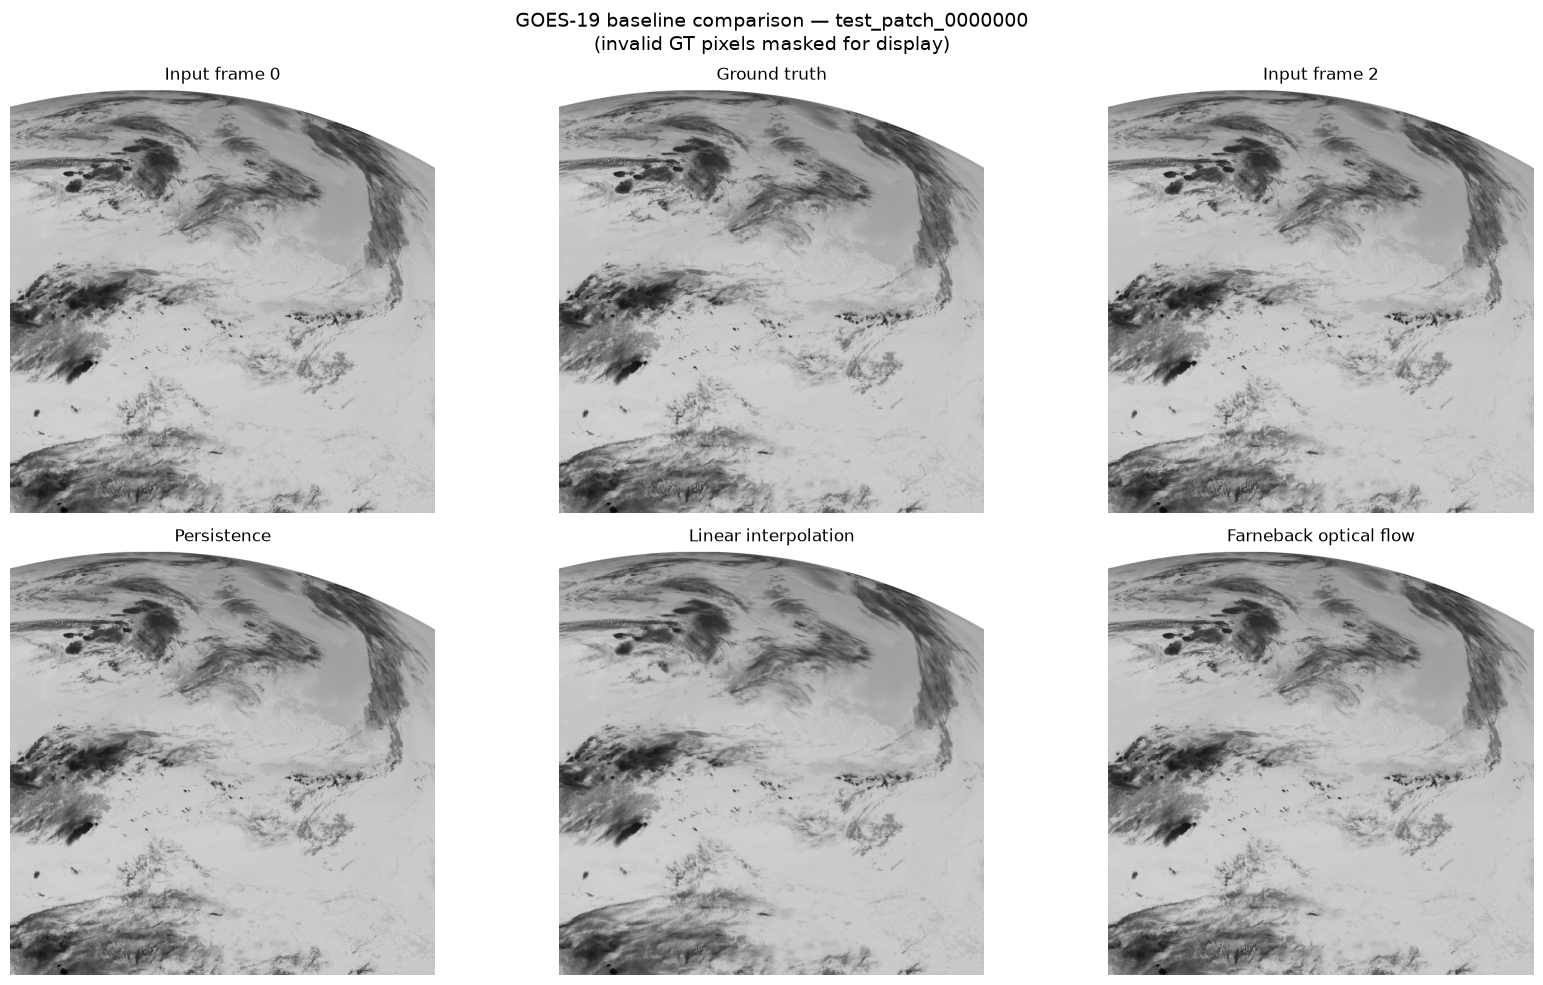


BASELINE EVALUATION COMPLETE
Patches evaluated: 1265
Total method results: 3795
Elapsed time: 185.07 minutes

Mean metrics across patches:
               method      MSE      PSNR     SSIM      MAE     RMSE     FSIM
Farneback_OpticalFlow 0.000179 37.660119 0.951904 0.006581 0.013245 0.997046
               Linear 0.000699 31.998029 0.876689 0.011828 0.025788 0.989758
          Persistence 0.001312 29.142318 0.836575 0.016564 0.035572 0.971046

Saved files:
Per-patch metrics: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/simple_baselines/baseline_metrics_per_patch.csv
Summary metrics: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/simple_baselines/baseline_metrics_summary.csv
Example visualization: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/simple_baselines/sample_predictions


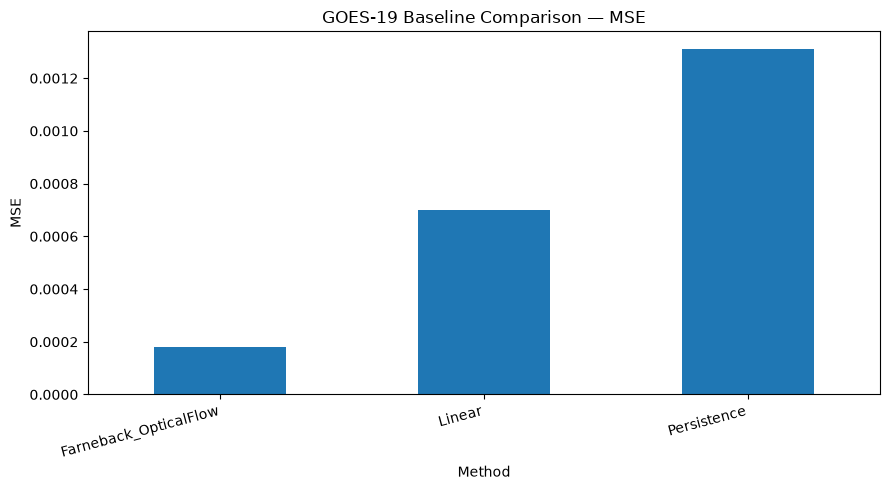

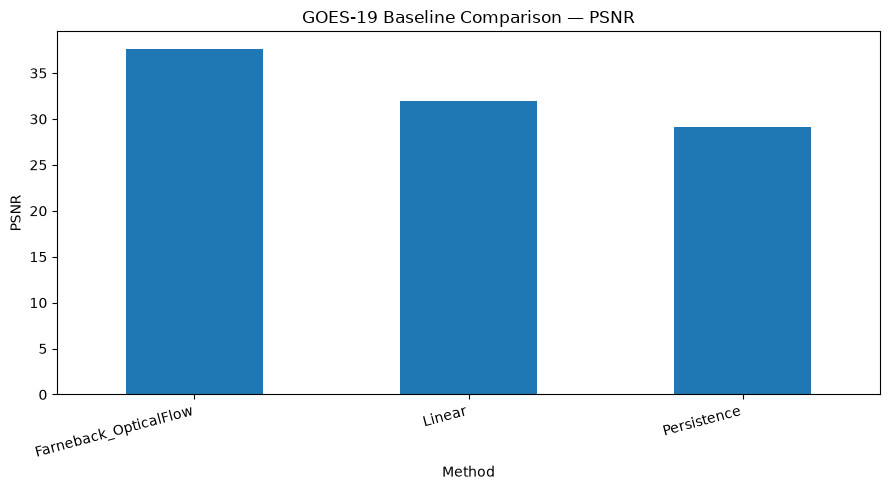

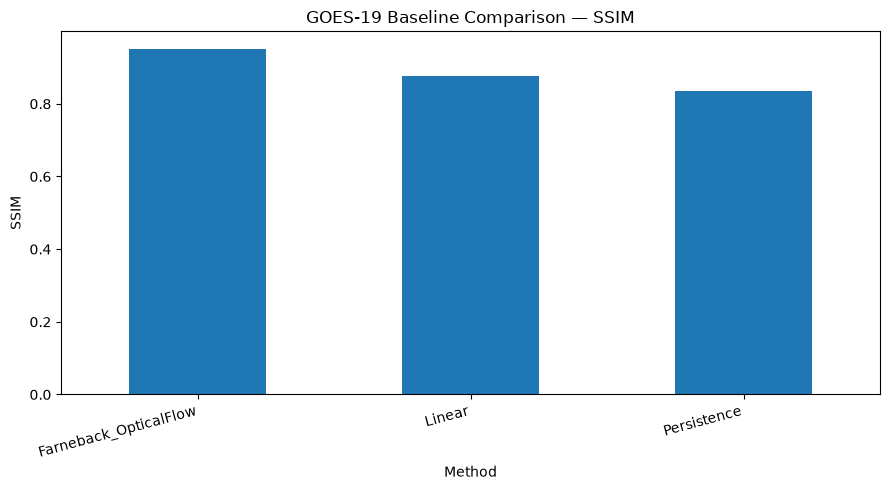

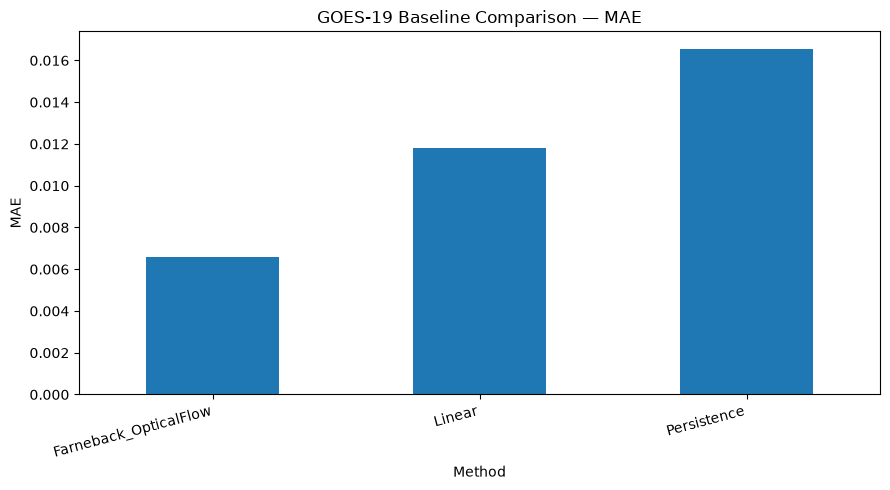

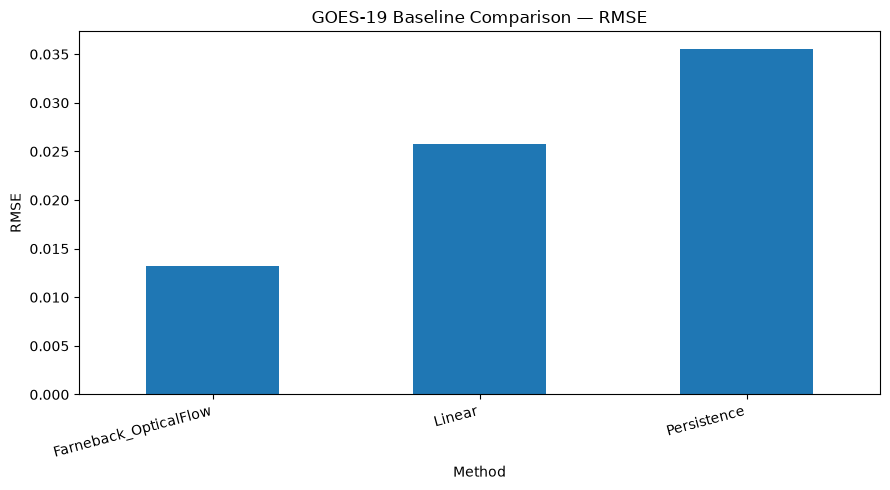

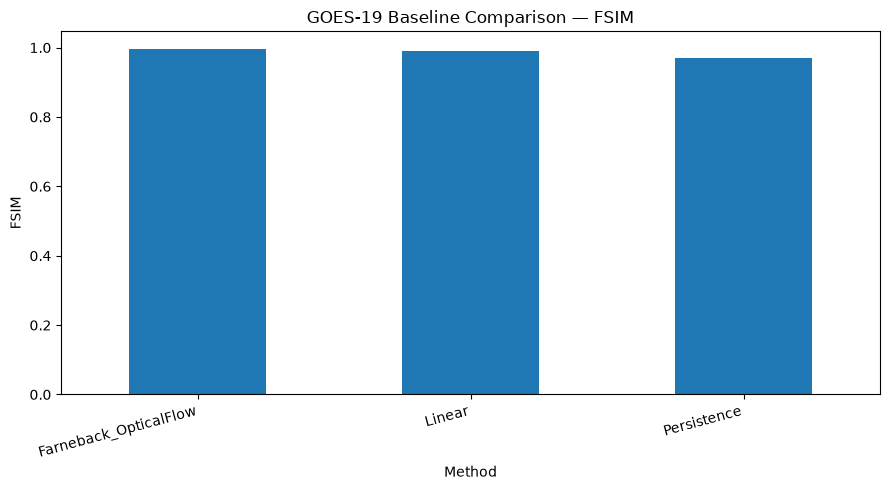


All baseline results and plots saved.


In [10]:

# ================================================================
# GOES-19 SIMPLE BASELINES — 2048 x 2048 TEST PATCHES
#
# Methods:
#   1. Persistence: prediction = img0
#   2. Linear interpolation: prediction = 0.5*(img0 + img2)
#   3. Farneback optical flow: symmetric half-warp + blend
#
# Metrics: MSE, PSNR, SSIM, MAE, RMSE, FSIM
# Uses GT validity masks; no training.
# ================================================================

import os
import time
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from skimage.metrics import structural_similarity

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ------------------------- PATHS ---------------------------------

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TEST_CSV = (
    PROJECT_DIR
    / "Dataset/GOES_TestPatches_2048/test_patches.csv"
)

OUTPUT_DIR = PROJECT_DIR / "results/simple_baselines"
PRED_DIR = OUTPUT_DIR / "sample_predictions"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR.mkdir(parents=True, exist_ok=True)

# Set to None to evaluate all patches.
# For a quick test first, change to 10.
MAX_PATCHES = None

# SSIM window size must be odd.
SSIM_WIN_SIZE = 7

# FSIM is optional because PIQ may not be installed.
TRY_FSIM = True

# Optical flow settings
FARNEBACK_PARAMS = dict(
    pyr_scale=0.5,
    levels=4,
    winsize=21,
    iterations=5,
    poly_n=7,
    poly_sigma=1.5,
    flags=0
)

# ------------------------- LOAD MANIFEST --------------------------

if not TEST_CSV.exists():
    raise FileNotFoundError(f"Test CSV not found: {TEST_CSV}")

df = pd.read_csv(TEST_CSV)

required_cols = [
    "patch_id",
    "img0_path",
    "gt_path",
    "img2_path",
    "mask0_path",
    "mask_gt_path",
    "mask2_path",
]

missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required CSV columns: {missing}")

if MAX_PATCHES is not None:
    df = df.head(MAX_PATCHES).copy()

print("=" * 72)
print("GOES-19 SIMPLE BASELINE EVALUATION")
print("=" * 72)
print("Manifest:", TEST_CSV)
print("Patches to evaluate:", len(df))
print("Output directory:", OUTPUT_DIR)
print("OpenCV:", cv2.__version__)

# ------------------------- OPTIONAL FSIM -------------------------

piq_available = False
if TRY_FSIM:
    try:
        import torch
        import piq
        piq_available = True
        fsim_device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )
        print("FSIM enabled on:", fsim_device)
    except Exception as e:
        print("FSIM unavailable; other metrics will still run.")
        print("Reason:", str(e)[:250])

# ------------------------- FILE HELPERS --------------------------

def load_npy(path_value):
    """Load a NumPy patch from a manifest path."""
    path = Path(str(path_value))
    if not path.exists():
        raise FileNotFoundError(f"Patch file does not exist: {path}")

    arr = np.load(path, allow_pickle=False)
    arr = np.asarray(arr)

    # Convert (1,H,W) or (H,W,1) to grayscale (H,W).
    arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale patch, got shape {arr.shape}: {path}"
        )

    return arr.astype(np.float32, copy=False)


def load_mask(path_value, shape):
    """Load mask and convert to a boolean valid-pixel mask."""
    if pd.isna(path_value) or str(path_value).strip() == "":
        return np.ones(shape, dtype=bool)

    path = Path(str(path_value))
    if not path.exists():
        raise FileNotFoundError(f"Mask file does not exist: {path}")

    mask = np.squeeze(np.load(path, allow_pickle=False))

    if mask.shape != shape:
        raise ValueError(
            f"Mask shape {mask.shape} does not match image shape {shape}: {path}"
        )

    # Handles boolean masks and numeric masks with 0/1 values.
    return np.isfinite(mask) & (mask > 0)


def robust_normalize(arr, valid_mask=None):
    """
    Patch values are expected to be normalized satellite images.
    Preserve values already in [0,1]. Otherwise normalize using
    the finite valid range for visualization/metric compatibility.
    """
    arr = np.asarray(arr, dtype=np.float32)
    finite = np.isfinite(arr)

    if valid_mask is not None:
        finite &= valid_mask

    if not finite.any():
        return np.zeros_like(arr, dtype=np.float32)

    vals = arr[finite]
    lo = float(vals.min())
    hi = float(vals.max())

    # Expected case for preprocessed patches.
    if lo >= -1e-5 and hi <= 1.00001:
        out = np.clip(arr, 0.0, 1.0)
    else:
        # Fallback only if patches are not already normalized.
        # Use shared target range later for consistency within a patch.
        out = arr.copy()
        out = np.clip(out, lo, hi)
        if hi > lo:
            out = (out - lo) / (hi - lo)
        else:
            out = np.zeros_like(arr)

    out[~np.isfinite(out)] = 0.0
    return out.astype(np.float32)


def masked_metrics(pred, gt, valid_mask):
    """MSE, PSNR, MAE, RMSE and masked-center SSIM."""
    pred = np.asarray(pred, dtype=np.float32)
    gt = np.asarray(gt, dtype=np.float32)

    valid = (
        valid_mask
        & np.isfinite(pred)
        & np.isfinite(gt)
    )

    if valid.sum() == 0:
        return {
            "MSE": np.nan,
            "PSNR": np.nan,
            "SSIM": np.nan,
            "MAE": np.nan,
            "RMSE": np.nan,
            "ValidPixels": 0,
        }

    error = pred[valid] - gt[valid]
    mse = float(np.mean(error ** 2))
    mae = float(np.mean(np.abs(error)))
    rmse = float(np.sqrt(mse))
    psnr = float("inf") if mse == 0 else float(
        10.0 * np.log10(1.0 / mse)
    )

    # Compute a local SSIM map and average only valid GT centers.
    # Invalid pixels are excluded from the final average, though they
    # can affect nearby SSIM windows near mask boundaries.
    _, ssim_map = structural_similarity(
        gt,
        pred,
        data_range=1.0,
        full=True,
        win_size=SSIM_WIN_SIZE
    )

    # Ignore a small border where a full SSIM window is unavailable.
    pad = SSIM_WIN_SIZE // 2
    center_valid = valid.copy()
    if pad > 0:
        center_valid[:pad, :] = False
        center_valid[-pad:, :] = False
        center_valid[:, :pad] = False
        center_valid[:, -pad:] = False

    ssim = (
        float(np.mean(ssim_map[center_valid]))
        if center_valid.any()
        else float("nan")
    )

    return {
        "MSE": mse,
        "PSNR": psnr,
        "SSIM": ssim,
        "MAE": mae,
        "RMSE": rmse,
        "ValidPixels": int(valid.sum()),
    }


def farneback_midpoint(img0, img2, valid0, valid2):
    """
    Symmetric midpoint approximation:
      - Estimate flow img0 -> img2 and img2 -> img0.
      - Warp each image halfway toward the midpoint.
      - Blend the two warped images.

    Inputs must be float32 [0,1].
    """
    a = np.clip(img0, 0, 1)
    b = np.clip(img2, 0, 1)

    # Farneback expects single-channel 8-bit or float32 images.
    a8 = np.round(a * 255.0).astype(np.uint8)
    b8 = np.round(b * 255.0).astype(np.uint8)

    # Replace invalid areas using nearest valid values before estimating
    # flow, preventing NaN/invalid values from entering OpenCV.
    # The masks are separately warped below to assess coverage.
    a_flow = a8.copy()
    b_flow = b8.copy()

    flow_0_to_2 = cv2.calcOpticalFlowFarneback(
        a_flow, b_flow, None, **FARNEBACK_PARAMS
    )
    flow_2_to_0 = cv2.calcOpticalFlowFarneback(
        b_flow, a_flow, None, **FARNEBACK_PARAMS
    )

    h, w = a.shape
    xx, yy = np.meshgrid(
        np.arange(w, dtype=np.float32),
        np.arange(h, dtype=np.float32)
    )

    # Sample img0 at coordinates that move halfway toward img2.
    map0_x = xx - 0.5 * flow_0_to_2[..., 0]
    map0_y = yy - 0.5 * flow_0_to_2[..., 1]

    # Sample img2 using reverse flow.
    map2_x = xx - 0.5 * flow_2_to_0[..., 0]
    map2_y = yy - 0.5 * flow_2_to_0[..., 1]

    warp0 = cv2.remap(
        a, map0_x, map0_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT101
    )
    warp2 = cv2.remap(
        b, map2_x, map2_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT101
    )

    # Warp masks too. Pixels outside the input mask coverage should
    # not contribute to the corresponding warped frame.
    m0 = cv2.remap(
        valid0.astype(np.float32), map0_x, map0_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )
    m2 = cv2.remap(
        valid2.astype(np.float32), map2_x, map2_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    good0 = m0 > 0.99
    good2 = m2 > 0.99

    both = good0 & good2
    only0 = good0 & ~good2
    only2 = good2 & ~good0

    prediction = 0.5 * (warp0 + warp2)
    prediction[only0] = warp0[only0]
    prediction[only2] = warp2[only2]

    # Where neither warped input is valid, use linear interpolation.
    fallback = 0.5 * (a + b)
    prediction[~(good0 | good2)] = fallback[~(good0 | good2)]

    return np.clip(prediction, 0, 1)


def calculate_fsim(pred, gt, valid_mask):
    """
    PIQ FSIM for grayscale images, if available.
    Uses chromatic=False for grayscale input.
    Computes FSIM over the patch; invalid pixels are replaced by GT
    before FSIM to reduce their influence. Treat as approximate when
    masks contain large invalid areas.
    """
    if not piq_available:
        return np.nan

    valid = valid_mask & np.isfinite(pred) & np.isfinite(gt)
    if not valid.any():
        return np.nan

    p = np.asarray(pred, dtype=np.float32).copy()
    g = np.asarray(gt, dtype=np.float32).copy()

    p[~valid] = g[~valid]

    p_tensor = torch.from_numpy(
        np.clip(p, 0, 1)[None, None, :, :]
    ).to(fsim_device)

    g_tensor = torch.from_numpy(
        np.clip(g, 0, 1)[None, None, :, :]
    ).to(fsim_device)

    with torch.no_grad():
        score = piq.fsim(
            p_tensor,
            g_tensor,
            data_range=1.0,
            chromatic=False
        )

    return float(score.item())


# ------------------------- EVALUATION ----------------------------

methods = [
    "Persistence",
    "Linear",
    "Farneback_OpticalFlow",
]

records = []
sample_saved = False
start_all = time.time()

for row in tqdm(
    df.itertuples(index=False),
    total=len(df),
    desc="Evaluating test patches"
):
    patch_id = str(row.patch_id)

    # Load arrays
    img0_raw = load_npy(row.img0_path)
    gt_raw = load_npy(row.gt_path)
    img2_raw = load_npy(row.img2_path)

    if img0_raw.shape != gt_raw.shape or img2_raw.shape != gt_raw.shape:
        raise ValueError(
            f"{patch_id}: shape mismatch: "
            f"img0={img0_raw.shape}, gt={gt_raw.shape}, "
            f"img2={img2_raw.shape}"
        )

    mask0 = load_mask(row.mask0_path, gt_raw.shape)
    mask_gt = load_mask(row.mask_gt_path, gt_raw.shape)
    mask2 = load_mask(row.mask2_path, gt_raw.shape)

    # Exclude nonfinite values from validity.
    mask0 &= np.isfinite(img0_raw)
    mask_gt &= np.isfinite(gt_raw)
    mask2 &= np.isfinite(img2_raw)

    # Normalize the three frames using one shared range per patch.
    # Standard preprocessed data should already be in [0,1].
    stack_valid = np.concatenate([
        img0_raw[mask0],
        gt_raw[mask_gt],
        img2_raw[mask2],
    ])

    if stack_valid.size == 0:
        print(f"Skipping {patch_id}: no valid pixels.")
        continue

    vmin = float(np.min(stack_valid))
    vmax = float(np.max(stack_valid))

    if vmin >= -1e-5 and vmax <= 1.00001:
        img0 = np.clip(img0_raw, 0, 1)
        gt = np.clip(gt_raw, 0, 1)
        img2 = np.clip(img2_raw, 0, 1)
    else:
        # Shared normalization keeps all three frames comparable.
        scale = vmax - vmin
        if scale < 1e-8:
            scale = 1.0
        img0 = np.clip((img0_raw - vmin) / scale, 0, 1)
        gt = np.clip((gt_raw - vmin) / scale, 0, 1)
        img2 = np.clip((img2_raw - vmin) / scale, 0, 1)

    # Replace invalid values with finite placeholders for the methods.
    img0 = np.nan_to_num(img0, nan=0.0, posinf=0.0, neginf=0.0)
    gt = np.nan_to_num(gt, nan=0.0, posinf=0.0, neginf=0.0)
    img2 = np.nan_to_num(img2, nan=0.0, posinf=0.0, neginf=0.0)

    # The metrics mask is based on GT validity.
    metric_mask = mask_gt.copy()

    predictions = {
        "Persistence": img0.copy(),
        "Linear": 0.5 * (img0 + img2),
    }

    # Optical flow is expensive at 2048 x 2048, but is run on the
    # original patch resolution for a fair spatial-resolution comparison.
    predictions["Farneback_OpticalFlow"] = farneback_midpoint(
        img0, img2, mask0, mask2
    )

    for method, pred in predictions.items():
        metrics = masked_metrics(pred, gt, metric_mask)

        fsim_score = calculate_fsim(pred, gt, metric_mask)

        records.append({
            "patch_id": patch_id,
            "method": method,
            **metrics,
            "FSIM": fsim_score,
            "image_height": gt.shape[0],
            "image_width": gt.shape[1],
        })

    # Save the first patch's visual comparison.
    if not sample_saved:
        fig, axes = plt.subplots(2, 3, figsize=(17, 10))

        display_items = [
            ("Input frame 0", img0),
            ("Ground truth", gt),
            ("Input frame 2", img2),
            ("Persistence", predictions["Persistence"]),
            ("Linear interpolation", predictions["Linear"]),
            ("Farneback optical flow", predictions["Farneback_OpticalFlow"]),
        ]

        for ax, (title, image) in zip(axes.flat, display_items):
            shown = np.ma.array(image, mask=~metric_mask)
            ax.imshow(shown, cmap="gray", vmin=0, vmax=1)
            ax.set_title(title)
            ax.axis("off")

        fig.suptitle(
            f"GOES-19 baseline comparison — {patch_id}\n"
            "(invalid GT pixels masked for display)",
            fontsize=14
        )
        plt.tight_layout()

        sample_plot = PRED_DIR / f"{patch_id}_comparison.png"
        plt.savefig(sample_plot, dpi=160, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        sample_saved = True

    # Periodically save progress so partial results survive interruption.
    if len(records) % (3 * 10) == 0:
        partial = pd.DataFrame(records)
        partial.to_csv(
            OUTPUT_DIR / "baseline_metrics_partial.csv",
            index=False
        )

# ------------------------- SAVE RESULTS --------------------------

results_df = pd.DataFrame(records)

if results_df.empty:
    raise RuntimeError("No patch results were generated.")

detail_csv = OUTPUT_DIR / "baseline_metrics_per_patch.csv"
results_df.to_csv(detail_csv, index=False)

metric_cols = [
    "MSE", "PSNR", "SSIM", "MAE", "RMSE", "FSIM"
]

summary = (
    results_df
    .groupby("method")[metric_cols]
    .mean(numeric_only=True)
    .reset_index()
)

summary_csv = OUTPUT_DIR / "baseline_metrics_summary.csv"
summary.to_csv(summary_csv, index=False)

print("\n" + "=" * 80)
print("BASELINE EVALUATION COMPLETE")
print("=" * 80)
print(f"Patches evaluated: {results_df['patch_id'].nunique()}")
print(f"Total method results: {len(results_df)}")
print(f"Elapsed time: {(time.time() - start_all) / 60:.2f} minutes")
print("\nMean metrics across patches:")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

print("\nSaved files:")
print("Per-patch metrics:", detail_csv)
print("Summary metrics:", summary_csv)
print("Example visualization:", PRED_DIR)

# ------------------------- METRIC PLOTS ---------------------------

for metric in metric_cols:
    plot_df = summary.set_index("method")[metric]

    plt.figure(figsize=(9, 5))
    plot_df.plot(kind="bar")
    plt.title(f"GOES-19 Baseline Comparison — {metric}")
    plt.ylabel(metric)
    plt.xlabel("Method")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()

    out_path = OUTPUT_DIR / f"comparison_{metric.lower()}.png"
    plt.savefig(out_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

print("\nAll baseline results and plots saved.")


In [2]:
%pip install h5py opencv-python scikit-image piq

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [7]:
# ================================================================
# INSAT-3DS SATELLITE FRAME INTERPOLATION — 30-MINUTE EVALUATION
#
# Methods:
#   1. Persistent Prediction
#   2. Linear Interpolation
#   3. Farneback Optical Flow
#
# Metrics:
#   MSE, PSNR, SSIM, MAE, RMSE, FSIM
#
# Input:  Frame at T
# GT:     Frame at T + 30 minutes
# Input:  Frame at T + 60 minutes
#
# Output:
#   - Per-triplet metrics CSV
#   - Summary metrics CSV
#   - Failed triplets CSV
#   - Predicted .npy arrays and PNG images
# ================================================================

import os
import re
import time
import warnings
from pathlib import Path
from datetime import datetime, timedelta

import cv2
import h5py
import numpy as np
import pandas as pd
import torch
import piq

from skimage.metrics import structural_similarity

warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

# Search this directory and its subdirectories for INSAT HDF5 files.
DATASET_DIR = PROJECT_DIR / "Dataset"

# If your HDF5 files are stored elsewhere, change DATASET_DIR above.

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "INSAT3DS_BASELINES_FULL_IMAGE_30MIN"
)

PREDICTION_DIR = OUTPUT_DIR / "predictions"
METRICS_DIR = OUTPUT_DIR / "metrics"

METHODS = [
    "Persistent",
    "Linear",
    "OpticalFlow",
]

# HDF5 image dataset
IMAGE_DATASET_KEY = "IMG_TIR1"

# Expected interval: 30 minutes between consecutive frames.
FRAME_INTERVAL_MINUTES = 30

# Process all possible triplets if None.
# Example: MAX_TRIPLETS = 10 to test only 10 triplets.
MAX_TRIPLETS = None

# Optional: set a specific GPU/CPU device for FSIM.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Shared normalization percentiles for each triplet.
LOWER_PERCENTILE = 1.0
UPPER_PERCENTILE = 99.0

# Optical flow parameters.
FLOW_PARAMS = {
    "pyr_scale": 0.5,
    "levels": 4,
    "winsize": 21,
    "iterations": 5,
    "poly_n": 7,
    "poly_sigma": 1.5,
    "flags": 0,
}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

for method in METHODS:
    (PREDICTION_DIR / method).mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("INSAT-3DS 30-MINUTE FRAME INTERPOLATION EVALUATION")
print("=" * 75)
print("Dataset directory :", DATASET_DIR)
print("Output directory  :", OUTPUT_DIR)
print("Device            :", DEVICE)
print("Image dataset key :", IMAGE_DATASET_KEY)
print("Frame interval    :", FRAME_INTERVAL_MINUTES, "minutes")
print("=" * 75)


# ================================================================
# 2. FIND HDF5 FILES
# ================================================================

def find_hdf5_files(root_dir):
    """Find HDF5 files recursively."""

    if not root_dir.exists():
        raise FileNotFoundError(
            f"Dataset directory does not exist: {root_dir}\n"
            "Please update DATASET_DIR to your actual HDF5 folder."
        )

    files = []

    for pattern in ("*.h5", "*.hdf5", "*.H5", "*.HDF5"):
        files.extend(root_dir.rglob(pattern))

    # Remove duplicate paths and sort.
    files = sorted(set(files))

    return files


# ================================================================
# 3. EXTRACT TIMESTAMP FROM FILENAME
# ================================================================

def extract_timestamp(file_path):
    """
    Expected filename pattern:
    3SIMG_07JUL2026_0000_L1B_STD_V01R00_B3.h5

    Extracts:
    07JUL2026_0000
    """

    pattern = r"(\d{2}[A-Z]{3}\d{4})_(\d{4})"

    match = re.search(pattern, file_path.name.upper())

    if match is None:
        return None

    date_part = match.group(1)
    time_part = match.group(2)

    timestamp_text = f"{date_part}_{time_part}"

    try:
        return datetime.strptime(
            timestamp_text,
            "%d%b%Y_%H%M"
        )
    except ValueError:
        return None


# ================================================================
# 4. READ IMAGE FROM HDF5
# ================================================================

def read_hdf5_image(file_path):
    """
    Read IMG_TIR1 from HDF5.

    Handles image shapes such as:
        (1, 2816, 2805)
        (2816, 2805)
    """

    with h5py.File(file_path, "r") as h5_file:

        if IMAGE_DATASET_KEY not in h5_file:
            raise KeyError(
                f"Dataset '{IMAGE_DATASET_KEY}' not found in {file_path.name}"
            )

        image = np.asarray(
            h5_file[IMAGE_DATASET_KEY][()]
        )

    # Remove leading singleton dimensions.
    image = np.squeeze(image)

    if image.ndim != 2:
        raise ValueError(
            f"Expected a 2D image after squeezing, "
            f"but got shape {image.shape} in {file_path.name}"
        )

    return image.astype(np.float32)


# ================================================================
# 5. BUILD 30-MINUTE TRIPLETS
# ================================================================

def build_triplets(hdf5_files):
    """
    Create triplets:
        Frame 0 = T
        Frame 1 = T + 30 minutes (ground truth)
        Frame 2 = T + 60 minutes

    Exact timestamp matching is used. Missing timestamps are skipped.
    """

    timestamp_to_file = {}

    for file_path in hdf5_files:

        timestamp = extract_timestamp(file_path)

        if timestamp is None:
            continue

        # Keep the first file for a timestamp.
        timestamp_to_file.setdefault(timestamp, file_path)

    timestamps = sorted(timestamp_to_file.keys())

    print("\nValid timestamped files:", len(timestamps))

    triplets = []

    interval = timedelta(minutes=FRAME_INTERVAL_MINUTES)
    total_span = interval * 2

    for t0 in timestamps:

        t1 = t0 + interval
        t2 = t0 + total_span

        if (
            t1 in timestamp_to_file
            and t2 in timestamp_to_file
        ):
            triplets.append({
                "time_0": t0,
                "time_1": t1,
                "time_2": t2,
                "file_0": timestamp_to_file[t0],
                "file_1": timestamp_to_file[t1],
                "file_2": timestamp_to_file[t2],
            })

    if MAX_TRIPLETS is not None:
        triplets = triplets[:MAX_TRIPLETS]

    return triplets


# ================================================================
# 6. NORMALIZE THE THREE FRAMES CONSISTENTLY
# ================================================================

def normalize_triplet(image_0, image_gt, image_2):
    """
    Use the same percentile-based normalization for all three frames.

    Returns:
        normalized frame 0
        normalized ground truth
        normalized frame 2
        shared valid mask
        normalization minimum
        normalization maximum

    Invalid pixels are represented by NaN in normalized arrays.
    """

    arrays = [image_0, image_gt, image_2]

    valid_arrays = []

    for image in arrays:
        finite_values = image[np.isfinite(image)]

        if finite_values.size == 0:
            raise ValueError("A frame contains no finite pixels.")

        valid_arrays.append(finite_values)

    combined_values = np.concatenate(valid_arrays)

    low = float(
        np.percentile(combined_values, LOWER_PERCENTILE)
    )

    high = float(
        np.percentile(combined_values, UPPER_PERCENTILE)
    )

    if not np.isfinite(low) or not np.isfinite(high):
        raise ValueError("Invalid normalization percentile values.")

    if high <= low:
        raise ValueError(
            f"Invalid normalization range: low={low}, high={high}"
        )

    normalized = []

    for image in arrays:

        image_normalized = (image - low) / (high - low)

        image_normalized = np.clip(
            image_normalized,
            0.0,
            1.0
        )

        image_normalized[~np.isfinite(image)] = np.nan

        normalized.append(
            image_normalized.astype(np.float32)
        )

    image_0_norm, gt_norm, image_2_norm = normalized

    # Only score pixels valid in all three frames.
    valid_mask = (
        np.isfinite(image_0_norm)
        & np.isfinite(gt_norm)
        & np.isfinite(image_2_norm)
    )

    if not np.any(valid_mask):
        raise ValueError("No common valid pixels across the triplet.")

    return (
        image_0_norm,
        gt_norm,
        image_2_norm,
        valid_mask,
        low,
        high,
    )


# ================================================================
# 7. PERSISTENT PREDICTION
# ================================================================

def predict_persistent(image_0, image_2):
    """
    Assume no change:
        predicted frame = first input frame
    """

    return image_0.copy()


# ================================================================
# 8. LINEAR INTERPOLATION
# ================================================================

def predict_linear(image_0, image_2):
    """
    Midpoint linear interpolation:
        prediction = 0.5 * frame_0 + 0.5 * frame_2
    """

    prediction = (
        0.5 * image_0
        + 0.5 * image_2
    )

    return prediction.astype(np.float32)


# ================================================================
# 9. FARNEBACK OPTICAL FLOW
# ================================================================

def predict_optical_flow(image_0, image_2):
    """
    Estimate flow from the first frame to the last frame.

    Warp both input frames approximately halfway toward the midpoint,
    then average their warped values.

    Note:
    This is a classical optical-flow baseline, not a trained model.
    """

    image_0_safe = np.nan_to_num(
        image_0,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    image_2_safe = np.nan_to_num(
        image_2,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    image_0_safe = np.clip(
        image_0_safe, 0.0, 1.0
    ).astype(np.float32)

    image_2_safe = np.clip(
        image_2_safe, 0.0, 1.0
    ).astype(np.float32)

    # Forward flow: frame 0 -> frame 2.
    flow_forward = cv2.calcOpticalFlowFarneback(
        image_0_safe,
        image_2_safe,
        None,
        **FLOW_PARAMS
    )

    # Backward flow: frame 2 -> frame 0.
    flow_backward = cv2.calcOpticalFlowFarneback(
        image_2_safe,
        image_0_safe,
        None,
        **FLOW_PARAMS
    )

    height, width = image_0_safe.shape

    grid_x, grid_y = np.meshgrid(
        np.arange(width, dtype=np.float32),
        np.arange(height, dtype=np.float32)
    )

    # Approximate half-time warping.
    map_x_0 = (
        grid_x - 0.5 * flow_forward[..., 0]
    )

    map_y_0 = (
        grid_y - 0.5 * flow_forward[..., 1]
    )

    map_x_2 = (
        grid_x - 0.5 * flow_backward[..., 0]
    )

    map_y_2 = (
        grid_y - 0.5 * flow_backward[..., 1]
    )

    warped_0 = cv2.remap(
        image_0_safe,
        map_x_0,
        map_y_0,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    warped_2 = cv2.remap(
        image_2_safe,
        map_x_2,
        map_y_2,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    prediction = 0.5 * (
        warped_0 + warped_2
    )

    return np.clip(
        prediction, 0.0, 1.0
    ).astype(np.float32)


# ================================================================
# 10. CALCULATE METRICS
# ================================================================

def calculate_metrics(prediction, target, valid_mask):
    """
    Calculate MSE, PSNR, SSIM, MAE, RMSE, and grayscale FSIM.

    MSE, PSNR, MAE and RMSE use only common valid pixels.

    SSIM and FSIM are calculated on full images after replacing
    invalid values with zero. Therefore, invalid areas can influence
    SSIM and FSIM near missing pixels.
    """

    prediction = np.asarray(
        prediction, dtype=np.float32
    )

    target = np.asarray(
        target, dtype=np.float32
    )

    valid_mask = np.asarray(
        valid_mask, dtype=bool
    )

    if prediction.shape != target.shape:
        raise ValueError(
            f"Shape mismatch: prediction {prediction.shape}, "
            f"target {target.shape}"
        )

    if prediction.ndim != 2:
        raise ValueError(
            f"Expected grayscale 2D images, got {prediction.ndim}D."
        )

    valid_mask = (
        valid_mask
        & np.isfinite(prediction)
        & np.isfinite(target)
    )

    if not np.any(valid_mask):
        raise ValueError("No valid pixels available for metrics.")

    # ------------------------------------------------------------
    # Pixelwise metrics: valid pixels only
    # ------------------------------------------------------------

    difference = (
        prediction[valid_mask].astype(np.float64)
        - target[valid_mask].astype(np.float64)
    )

    mse = float(
        np.mean(difference ** 2)
    )

    mae = float(
        np.mean(np.abs(difference))
    )

    rmse = float(
        np.sqrt(mse)
    )

    if mse == 0:
        psnr = float("inf")
    else:
        # Images normalized to [0, 1], so MAX_I = 1.
        psnr = float(
            10.0 * np.log10(1.0 / mse)
        )

    # ------------------------------------------------------------
    # SSIM: replace invalid pixels before full-image calculation
    # ------------------------------------------------------------

    prediction_safe = np.nan_to_num(
        prediction,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    target_safe = np.nan_to_num(
        target,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    prediction_safe = np.clip(
        prediction_safe, 0.0, 1.0
    )

    target_safe = np.clip(
        target_safe, 0.0, 1.0
    )

    ssim = float(
        structural_similarity(
            target_safe,
            prediction_safe,
            data_range=1.0,
            gaussian_weights=True,
            sigma=1.5,
            use_sample_covariance=False
        )
    )

    # ------------------------------------------------------------
    # FSIM: grayscale mode
    # ------------------------------------------------------------

    prediction_tensor = torch.from_numpy(
        np.ascontiguousarray(
            prediction_safe.astype(np.float32)
        )
    )[None, None, :, :].to(DEVICE)

    target_tensor = torch.from_numpy(
        np.ascontiguousarray(
            target_safe.astype(np.float32)
        )
    )[None, None, :, :].to(DEVICE)

    with torch.no_grad():

        fsim_tensor = piq.fsim(
            prediction_tensor,
            target_tensor,
            data_range=1.0,
            chromatic=False,
            reduction="mean"
        )

    fsim = float(
        fsim_tensor.item()
    )

    return {
        "MSE": mse,
        "PSNR": psnr,
        "SSIM": ssim,
        "MAE": mae,
        "RMSE": rmse,
        "FSIM": fsim,
        "Valid_Pixels": int(np.count_nonzero(valid_mask)),
    }


# ================================================================
# 11. SAVE PREDICTION ARRAYS AND PNG IMAGES
# ================================================================

def save_prediction(prediction, method, triplet_id):
    """Save the normalized prediction as NPY and PNG."""

    method_dir = PREDICTION_DIR / method

    method_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    npy_path = (
        method_dir
        / f"{triplet_id}_prediction.npy"
    )

    png_path = (
        method_dir
        / f"{triplet_id}_prediction.png"
    )

    prediction_safe = np.nan_to_num(
        prediction,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    prediction_safe = np.clip(
        prediction_safe, 0.0, 1.0
    )

    np.save(
        npy_path,
        prediction_safe.astype(np.float32)
    )

    prediction_uint8 = (
        prediction_safe * 255.0
    ).round().astype(np.uint8)

    cv2.imwrite(
        str(png_path),
        prediction_uint8
    )


# ================================================================
# 12. MAIN EVALUATION
# ================================================================

hdf5_files = find_hdf5_files(DATASET_DIR)

print("\nTotal HDF5 files found:", len(hdf5_files))

if len(hdf5_files) == 0:
    raise RuntimeError(
        f"No HDF5 files found under {DATASET_DIR}. "
        "Please check DATASET_DIR."
    )

triplets = build_triplets(hdf5_files)

print("30-minute triplets found:", len(triplets))

if len(triplets) == 0:
    raise RuntimeError(
        "No complete 30-minute triplets found.\n"
        "This code requires frames at T, T+30, and T+60 minutes.\n"
        "Check filenames and whether timestamps are present at "
        "30-minute intervals."
    )

all_results = []
failed_results = []

start_time = time.time()

for index, triplet in enumerate(triplets, start=1):

    time_0 = triplet["time_0"]
    time_gt = triplet["time_1"]
    time_2 = triplet["time_2"]

    triplet_id = (
        f"triplet_{index:05d}_"
        f"{time_0.strftime('%Y%m%d_%H%M')}"
    )

    print("\n" + "-" * 75)
    print(f"[{index}/{len(triplets)}] {triplet_id}")
    print("Input frame 1 :", time_0)
    print("Ground truth  :", time_gt)
    print("Input frame 2 :", time_2)

    try:

        # --------------------------------------------------------
        # Load the three source images
        # --------------------------------------------------------

        image_0_raw = read_hdf5_image(
            triplet["file_0"]
        )

        gt_raw = read_hdf5_image(
            triplet["file_1"]
        )

        image_2_raw = read_hdf5_image(
            triplet["file_2"]
        )

        if not (
            image_0_raw.shape
            == gt_raw.shape
            == image_2_raw.shape
        ):
            raise ValueError(
                "Image shape mismatch: "
                f"{image_0_raw.shape}, "
                f"{gt_raw.shape}, "
                f"{image_2_raw.shape}"
            )

        # --------------------------------------------------------
        # Normalize all three frames consistently
        # --------------------------------------------------------

        (
            image_0,
            gt,
            image_2,
            valid_mask,
            norm_low,
            norm_high,
        ) = normalize_triplet(
            image_0_raw,
            gt_raw,
            image_2_raw
        )

        print("Image shape:", image_0.shape)
        print("Valid pixels:", int(valid_mask.sum()))
        print(
            f"Normalization range: "
            f"{norm_low:.6f} to {norm_high:.6f}"
        )

        # --------------------------------------------------------
        # Generate predictions
        # --------------------------------------------------------

        predictions = {
            "Persistent": predict_persistent(
                image_0, image_2
            ),

            "Linear": predict_linear(
                image_0, image_2
            ),

            "OpticalFlow": predict_optical_flow(
                image_0, image_2
            ),
        }

        # --------------------------------------------------------
        # Evaluate each prediction
        # --------------------------------------------------------

        for method in METHODS:

            prediction = predictions[method]

            metrics = calculate_metrics(
                prediction=prediction,
                target=gt,
                valid_mask=valid_mask
            )

            result = {
                "Triplet_ID": triplet_id,
                "Method": method,
                "Time_0": time_0.isoformat(),
                "Ground_Truth_Time": time_gt.isoformat(),
                "Time_2": time_2.isoformat(),
                "File_0": str(triplet["file_0"]),
                "Ground_Truth_File": str(triplet["file_1"]),
                "File_2": str(triplet["file_2"]),
                "Height": int(gt.shape[0]),
                "Width": int(gt.shape[1]),
                "Normalization_Low": norm_low,
                "Normalization_High": norm_high,
                **metrics,
            }

            all_results.append(result)

            save_prediction(
                prediction,
                method,
                triplet_id
            )

            print(
                f"{method:12s} | "
                f"MSE={metrics['MSE']:.8f} | "
                f"PSNR={metrics['PSNR']:.4f} dB | "
                f"SSIM={metrics['SSIM']:.6f} | "
                f"MAE={metrics['MAE']:.8f} | "
                f"RMSE={metrics['RMSE']:.8f} | "
                f"FSIM={metrics['FSIM']:.6f}"
            )

    except Exception as error:

        print("ERROR:", repr(error))

        failed_results.append({
            "Triplet_ID": triplet_id,
            "Time_0": time_0.isoformat(),
            "Ground_Truth_Time": time_gt.isoformat(),
            "Time_2": time_2.isoformat(),
            "File_0": str(triplet["file_0"]),
            "Ground_Truth_File": str(triplet["file_1"]),
            "File_2": str(triplet["file_2"]),
            "Error": repr(error),
        })

    # Save intermediate results in case the notebook stops.
    if all_results:
        pd.DataFrame(all_results).to_csv(
            METRICS_DIR / "per_triplet_metrics.csv",
            index=False
        )

    if failed_results:
        pd.DataFrame(failed_results).to_csv(
            METRICS_DIR / "failed_triplets.csv",
            index=False
        )


# ================================================================
# 13. SAVE FINAL PER-TRIPLET METRICS
# ================================================================

per_triplet_path = (
    METRICS_DIR / "per_triplet_metrics.csv"
)

if all_results:

    results_df = pd.DataFrame(all_results)

    results_df.to_csv(
        per_triplet_path,
        index=False
    )

    print("\nPer-triplet metrics saved:")
    print(per_triplet_path)

else:

    print("\nNo successful evaluations were completed.")


# ================================================================
# 14. CALCULATE SUMMARY METRICS
# ================================================================

if all_results:

    results_df = pd.DataFrame(all_results)

    metric_columns = [
        "MSE",
        "PSNR",
        "SSIM",
        "MAE",
        "RMSE",
        "FSIM",
    ]

    summary_df = (
        results_df
        .groupby("Method")[metric_columns]
        .agg(["mean", "std", "median"])
    )

    # Flatten the multi-level column names.
    summary_df.columns = [
        f"{metric}_{stat}"
        for metric, stat in summary_df.columns
    ]

    summary_df = summary_df.reset_index()

    summary_path = (
        METRICS_DIR / "summary_metrics.csv"
    )

    summary_df.to_csv(
        summary_path,
        index=False
    )

    print("\n" + "=" * 100)
    print("SUMMARY RESULTS — ALL SUCCESSFUL TRIPLETS")
    print("=" * 100)

    print(
        summary_df.to_string(
            index=False,
            float_format=lambda value: f"{value:.6f}"
        )
    )

    print("\nSummary CSV saved:")
    print(summary_path)

    # ------------------------------------------------------------
    # Best mean score for each metric
    # ------------------------------------------------------------

    print("\n" + "=" * 75)
    print("BEST METHOD FOR EACH METRIC")
    print("=" * 75)

    for metric in metric_columns:

        means = results_df.groupby("Method")[metric].mean()

        if metric in ["MSE", "MAE", "RMSE"]:
            best_method = means.idxmin()
            best_value = means.min()
            direction = "lower is better"
        else:
            best_method = means.idxmax()
            best_value = means.max()
            direction = "higher is better"

        print(
            f"{metric:8s}: "
            f"{best_method:12s} = {best_value:.6f} "
            f"({direction})"
        )


# ================================================================
# 15. SAVE FAILED TRIPLETS
# ================================================================

failed_path = (
    METRICS_DIR / "failed_triplets.csv"
)

if failed_results:

    failed_df = pd.DataFrame(failed_results)

    failed_df.to_csv(
        failed_path,
        index=False
    )

    print("\nFailed triplets:", len(failed_df))
    print("Failure report:", failed_path)

else:

    pd.DataFrame(
        columns=[
            "Triplet_ID",
            "Time_0",
            "Ground_Truth_Time",
            "Time_2",
            "File_0",
            "Ground_Truth_File",
            "File_2",
            "Error",
        ]
    ).to_csv(
        failed_path,
        index=False
    )

    print("\nNo failed triplets.")


# ================================================================
# 16. FINAL REPORT
# ================================================================

elapsed_seconds = time.time() - start_time

print("\n" + "=" * 75)
print("EVALUATION COMPLETED")
print("=" * 75)

print("Triplets discovered :", len(triplets))
print(
    "Successful triplets :",
    len(set(
        row["Triplet_ID"]
        for row in all_results
    ))
)
print("Failed triplets     :", len(failed_results))
print(f"Elapsed time        : {elapsed_seconds / 60:.2f} minutes")

print("\nOutput files:")
print("1. Per-triplet metrics:", per_triplet_path)
print("2. Summary metrics    :", METRICS_DIR / "summary_metrics.csv")
print("3. Failed triplets    :", failed_path)
print("4. Predictions        :", PREDICTION_DIR)

print("\nPrediction subfolders:")

for method in METHODS:
    print(" -", PREDICTION_DIR / method)

print("\nMetric interpretation:")
print(" - MSE, MAE, RMSE: lower is better.")
print(" - PSNR, SSIM, FSIM: generally higher is better.")
print("=" * 75)

INSAT-3DS 30-MINUTE FRAME INTERPOLATION EVALUATION
Dataset directory : /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset
Output directory  : /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/INSAT3DS_BASELINES_FULL_IMAGE_30MIN
Device            : cuda
Image dataset key : IMG_TIR1
Frame interval    : 30 minutes

Total HDF5 files found: 426

Valid timestamped files: 426
30-minute triplets found: 416

---------------------------------------------------------------------------
[1/416] triplet_00001_20260707_0000
Input frame 1 : 2026-07-07 00:00:00
Ground truth  : 2026-07-07 00:30:00
Input frame 2 : 2026-07-07 01:00:00
Image shape: (2816, 2805)
Valid pixels: 7898880
Normalization range: 505.000000 to 1023.000000
Persistent   | MSE=0.00279155 | PSNR=25.5416 dB | SSIM=0.742924 | MAE=0.02657402 | RMSE=0.05283508 | FSIM=0.967550
Linear       | MSE=0.00153230 | PSNR=28.1465 dB | SSIM=0.792211 | MAE=0.01942182 | RMSE=0.03914466 | FSIM=0.988920
OpticalFlow  | MSE=0.00153230

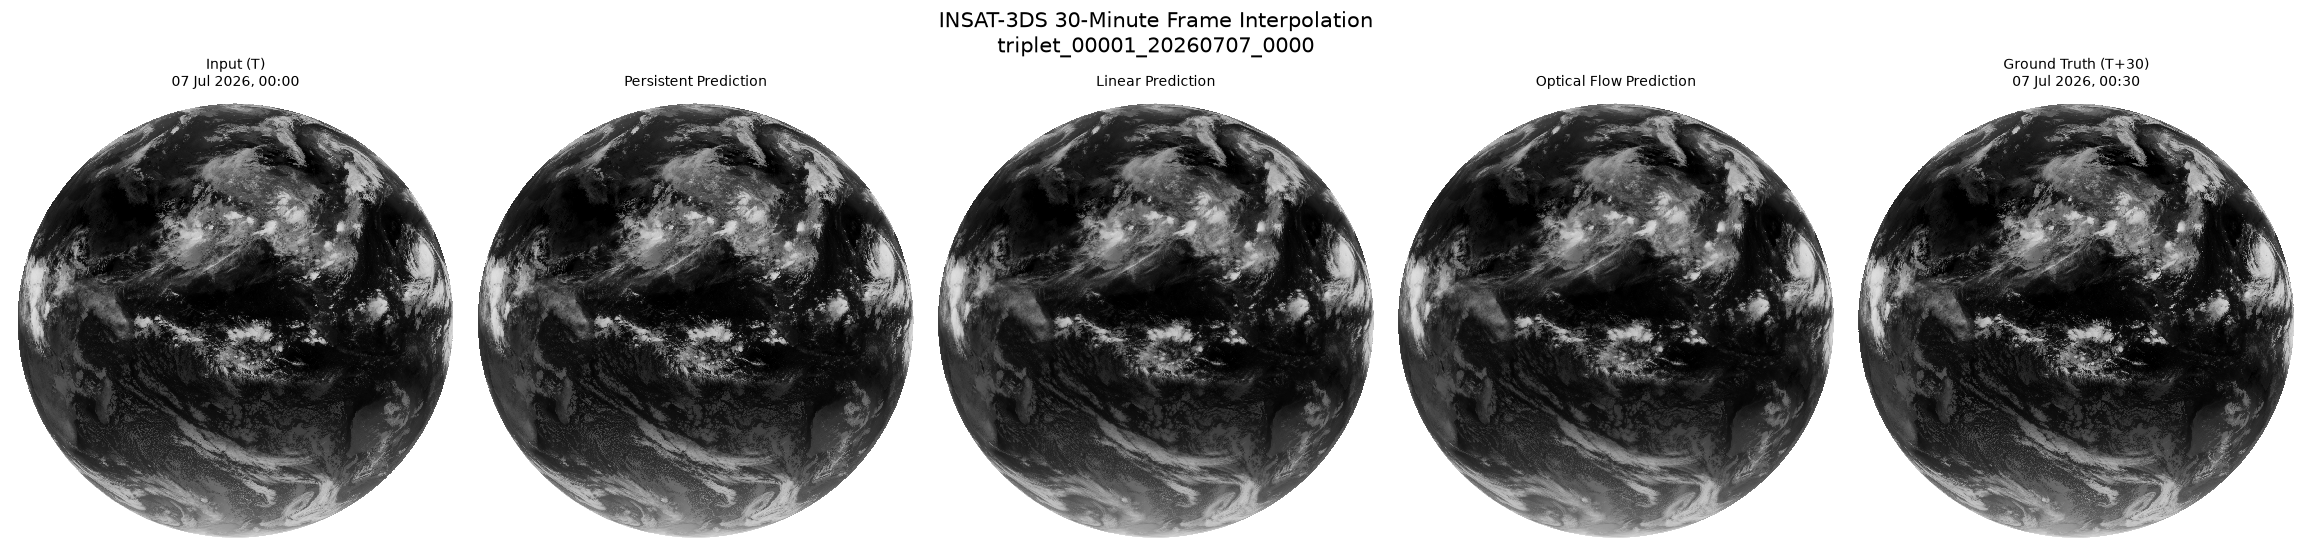

Triplet: triplet_00001_20260707_0000
Input file: 3SIMG_07JUL2026_0000_L1B_STD_V01R00_B3.h5
Ground-truth file: 3SIMG_07JUL2026_0030_L1B_STD_V01R00_B3.h5


,Method,MSE,PSNR,SSIM,MAE,RMSE,FSIM
0,Persistent,0.002792,25.541552,0.742924,0.026574,0.052835,0.96755
1,Linear,0.001532,28.146549,0.792211,0.019422,0.039145,0.98892
2,OpticalFlow,0.001532,28.146549,0.792211,0.019422,0.039145,0.98892


In [8]:
# ================================================================
# INSAT-3DS: INPUT vs PREDICTIONS vs GROUND TRUTH
#
# Panels:
#   1. Input frame at T
#   2. Persistent prediction
#   3. Linear prediction
#   4. Optical Flow prediction
#   5. Ground Truth at T+30 minutes
#
# Uses the output folders from the previous evaluation code.
# ================================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import h5py
import re
from datetime import datetime

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

DATASET_DIR = PROJECT_DIR / "Dataset"

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "INSAT3DS_BASELINES_FULL_IMAGE_30MIN"
)

PREDICTION_DIR = OUTPUT_DIR / "predictions"

METRICS_CSV = (
    OUTPUT_DIR / "metrics" / "per_triplet_metrics.csv"
)

IMAGE_DATASET_KEY = "IMG_TIR1"

# Choose the triplet number to visualize.
# Example: 1 means the first successfully evaluated triplet.
TRIPLET_NUMBER = 1

# Optional: crop a region to inspect details.
# None displays the full image.
# Example: CROP = (500, 1500, 500, 1500)
#          (y_start, y_end, x_start, x_end)
CROP = None


# ------------------------------------------------
# 2. FIND HDF5 FILES AND TIMESTAMPS
# ------------------------------------------------

def extract_timestamp(path):
    match = re.search(
        r"(\d{2}[A-Z]{3}\d{4})_(\d{4})",
        path.name.upper()
    )

    if match is None:
        return None

    try:
        return datetime.strptime(
            match.group(1) + "_" + match.group(2),
            "%d%b%Y_%H%M"
        )
    except ValueError:
        return None


h5_files = []

for pattern in ("*.h5", "*.hdf5", "*.H5", "*.HDF5"):
    h5_files.extend(DATASET_DIR.rglob(pattern))

timestamp_map = {}

for path in sorted(set(h5_files)):
    timestamp = extract_timestamp(path)

    if timestamp is not None:
        timestamp_map.setdefault(timestamp, path)

timestamps = sorted(timestamp_map)

# Find triplets at T, T+30 and T+60 minutes.
triplets = []

from datetime import timedelta

for t0 in timestamps:
    t1 = t0 + timedelta(minutes=30)
    t2 = t0 + timedelta(minutes=60)

    if t1 in timestamp_map and t2 in timestamp_map:
        triplets.append({
            "time_0": t0,
            "time_gt": t1,
            "time_2": t2,
            "file_0": timestamp_map[t0],
            "file_gt": timestamp_map[t1],
            "file_2": timestamp_map[t2],
        })


# ------------------------------------------------
# 3. LOAD METRICS TO IDENTIFY SUCCESSFUL TRIPLETS
# ------------------------------------------------

import pandas as pd

if not METRICS_CSV.exists():
    raise FileNotFoundError(
        f"Metrics CSV not found: {METRICS_CSV}\n"
        "Run the evaluation code first."
    )

metrics_df = pd.read_csv(METRICS_CSV)

successful_ids = (
    metrics_df["Triplet_ID"]
    .drop_duplicates()
    .tolist()
)

if TRIPLET_NUMBER < 1 or TRIPLET_NUMBER > len(successful_ids):
    raise ValueError(
        f"TRIPLET_NUMBER must be between 1 and "
        f"{len(successful_ids)}."
    )

triplet_id = successful_ids[TRIPLET_NUMBER - 1]

# Extract timestamp from the ID generated by the evaluation code.
match = re.search(
    r"triplet_\d+_(\d{8}_\d{4})",
    triplet_id
)

if match is None:
    raise ValueError(
        f"Could not extract timestamp from {triplet_id}"
    )

target_time = datetime.strptime(
    match.group(1),
    "%Y%m%d_%H%M"
)

triplet = next(
    (
        item for item in triplets
        if item["time_0"] == target_time
    ),
    None
)

if triplet is None:
    raise ValueError(
        f"Could not find original HDF5 triplet for {triplet_id}."
    )


# ------------------------------------------------
# 4. READ ORIGINAL HDF5 IMAGES
# ------------------------------------------------

def read_image(path):
    with h5py.File(path, "r") as f:
        image = np.asarray(f[IMAGE_DATASET_KEY][()])

    image = np.squeeze(image)

    if image.ndim != 2:
        raise ValueError(
            f"Expected 2D image; received {image.shape}"
        )

    return image.astype(np.float32)


image_0_raw = read_image(triplet["file_0"])
gt_raw = read_image(triplet["file_gt"])
image_2_raw = read_image(triplet["file_2"])


# ------------------------------------------------
# 5. USE THE SAME NORMALIZATION AS EVALUATION
# ------------------------------------------------

all_values = np.concatenate([
    image_0_raw[np.isfinite(image_0_raw)],
    gt_raw[np.isfinite(gt_raw)],
    image_2_raw[np.isfinite(image_2_raw)]
])

low = np.percentile(all_values, 1)
high = np.percentile(all_values, 99)

def normalize_image(image):
    result = (image - low) / (high - low)
    result = np.clip(result, 0, 1).astype(np.float32)
    result[~np.isfinite(image)] = np.nan
    return result

input_image = normalize_image(image_0_raw)
gt_image = normalize_image(gt_raw)


# ------------------------------------------------
# 6. LOAD SAVED PREDICTIONS
# ------------------------------------------------

def load_prediction(method, triplet_id):
    path = (
        PREDICTION_DIR
        / method
        / f"{triplet_id}_prediction.npy"
    )

    if not path.exists():
        raise FileNotFoundError(
            f"Prediction not found: {path}"
        )

    return np.load(path).astype(np.float32)


persistent_pred = load_prediction(
    "Persistent", triplet_id
)

linear_pred = load_prediction(
    "Linear", triplet_id
)

opticalflow_pred = load_prediction(
    "OpticalFlow", triplet_id
)


# ------------------------------------------------
# 7. OPTIONAL CROP
# ------------------------------------------------

def crop_image(image):
    if CROP is None:
        return image

    y1, y2, x1, x2 = CROP
    return image[y1:y2, x1:x2]


images = [
    crop_image(input_image),
    crop_image(persistent_pred),
    crop_image(linear_pred),
    crop_image(opticalflow_pred),
    crop_image(gt_image),
]

titles = [
    f"Input (T)\n{triplet['time_0']:%d %b %Y, %H:%M}",
    "Persistent Prediction",
    "Linear Prediction",
    "Optical Flow Prediction",
    f"Ground Truth (T+30)\n{triplet['time_gt']:%d %b %Y, %H:%M}",
]


# ------------------------------------------------
# 8. PLOT ALL FIVE IMAGES
# ------------------------------------------------

fig, axes = plt.subplots(
    1, 5,
    figsize=(23, 5.5),
    constrained_layout=True
)

for ax, image, title in zip(axes, images, titles):
    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(title, fontsize=10)
    ax.axis("off")

fig.suptitle(
    f"INSAT-3DS 30-Minute Frame Interpolation\n{triplet_id}",
    fontsize=15
)

plt.show()


# ------------------------------------------------
# 9. PRINT METRICS FOR THIS TRIPLET
# ------------------------------------------------

selected_metrics = metrics_df[
    metrics_df["Triplet_ID"] == triplet_id
].copy()

display_columns = [
    "Method", "MSE", "PSNR", "SSIM", "MAE", "RMSE", "FSIM"
]

print("Triplet:", triplet_id)
print("Input file:", triplet["file_0"].name)
print("Ground-truth file:", triplet["file_gt"].name)

display(
    selected_metrics[display_columns].round(6)
)

INSAT-3DS FRAME INTERPOLATION
Selected triplet: triplet_00001_20260707_0000
Input 1 time    : 2026-07-07 00:00:00
Ground truth    : 2026-07-07 00:30:00
Input 2 time    : 2026-07-07 01:00:00

Original files:
Input 1: 3SIMG_07JUL2026_0000_L1B_STD_V01R00_B3.h5
GT     : 3SIMG_07JUL2026_0030_L1B_STD_V01R00_B3.h5
Input 2: 3SIMG_07JUL2026_0100_L1B_STD_V01R00_B3.h5

Original image dimensions: (2816, 2805)


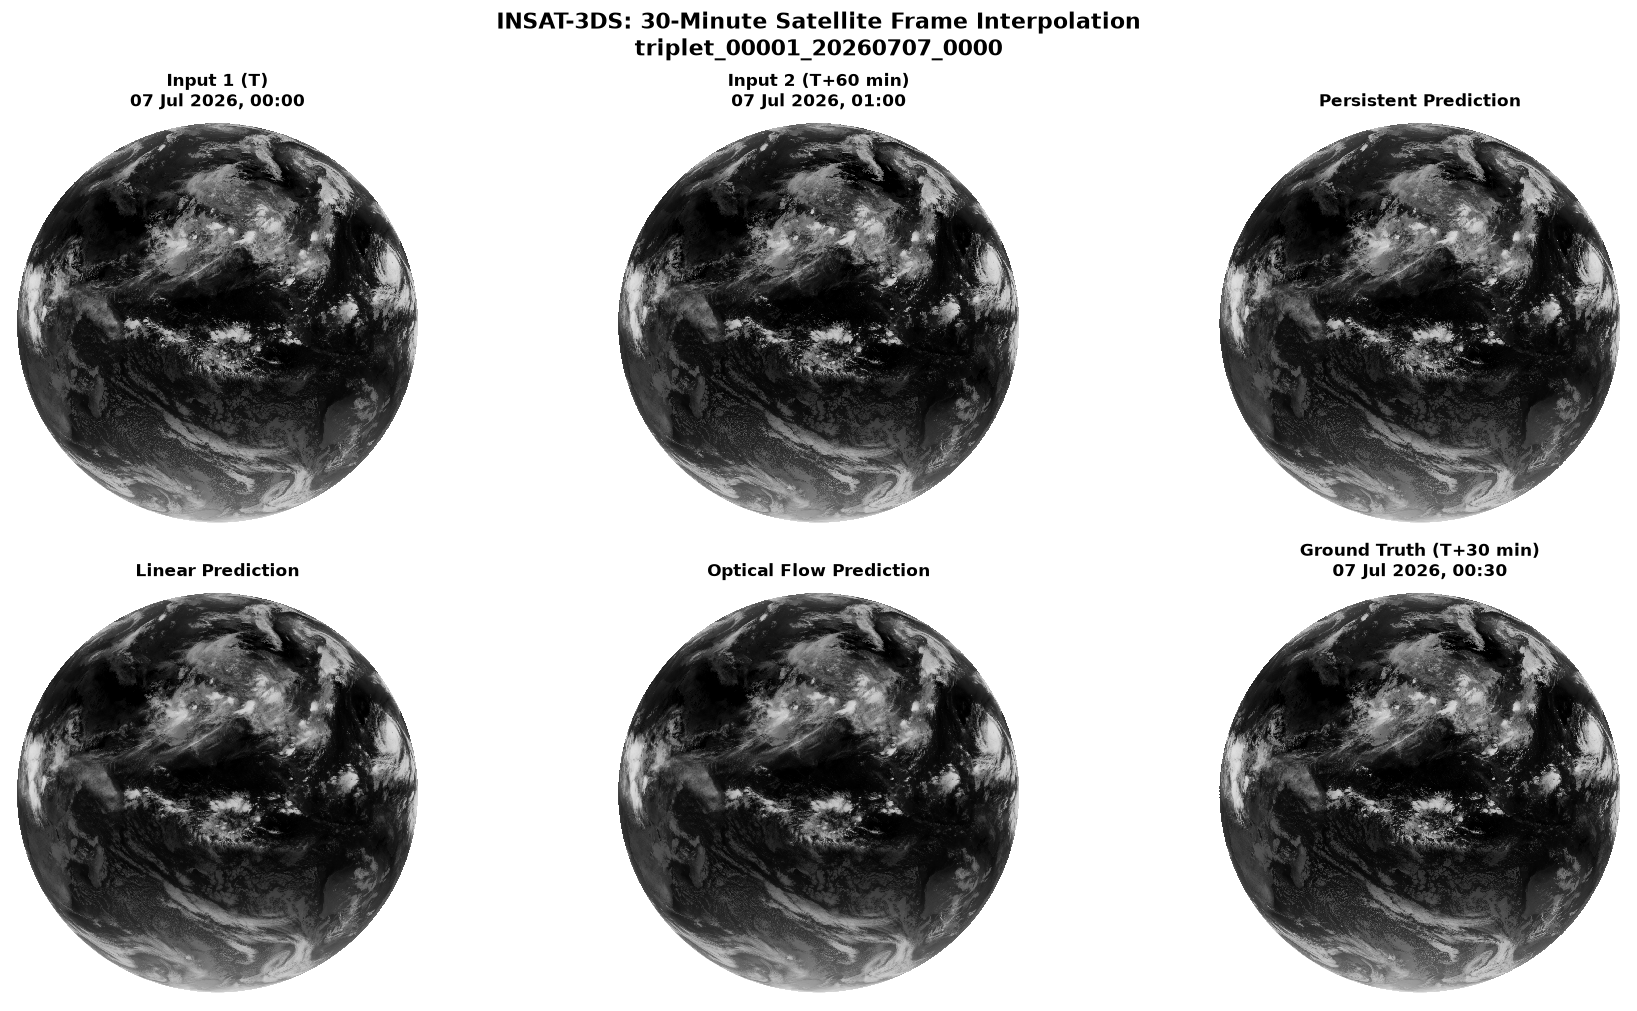


Visualization saved to:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/INSAT3DS_BASELINES_FULL_IMAGE_30MIN/visualizations/triplet_00001_20260707_0000_six_image_comparison.png

Metrics for the selected triplet:


,Method,MSE,PSNR,SSIM,MAE,RMSE,FSIM
0,Persistent,0.002792,25.541552,0.742924,0.026574,0.052835,0.96755
1,Linear,0.001532,28.146549,0.792211,0.019422,0.039145,0.98892
2,OpticalFlow,0.001532,28.146549,0.792211,0.019422,0.039145,0.98892



Completed successfully.


In [9]:
# ================================================================
# INSAT-3DS: COMPLETE 30-MINUTE FRAME INTERPOLATION VISUALIZATION
#
# Original triplet:
#   Input 1       = Frame at T
#   Ground Truth  = Frame at T + 30 minutes
#   Input 2       = Frame at T + 60 minutes
#
# Predictions:
#   1. Persistent
#   2. Linear
#   3. Farneback Optical Flow
#
# Total: 6 images
#
# 1. Input 1 (T)
# 2. Input 2 (T+60)
# 3. Persistent prediction
# 4. Linear prediction
# 5. Optical Flow prediction
# 6. Ground Truth (T+30)
# ================================================================

from pathlib import Path
from datetime import datetime, timedelta
import re

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ================================================================
# 1. CONFIGURATION
# ================================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

DATASET_DIR = PROJECT_DIR / "Dataset"

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "INSAT3DS_BASELINES_FULL_IMAGE_30MIN"
)

PREDICTION_DIR = OUTPUT_DIR / "predictions"

METRICS_CSV = (
    OUTPUT_DIR
    / "metrics"
    / "per_triplet_metrics.csv"
)

IMAGE_DATASET_KEY = "IMG_TIR1"

# Change this to view another successfully evaluated triplet.
TRIPLET_NUMBER = 1

# None = show full satellite images.
# Example: (500, 1500, 500, 1500) shows a cropped region.
# Format: (y_start, y_end, x_start, x_end)
CROP = None

# ================================================================
# 2. CHECK REQUIRED FILES
# ================================================================

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}"
    )

if not METRICS_CSV.exists():
    raise FileNotFoundError(
        f"Metrics CSV not found: {METRICS_CSV}\n"
        "Run the evaluation code first."
    )

metrics_df = pd.read_csv(METRICS_CSV)

required_columns = {
    "Triplet_ID", "Method", "MSE", "PSNR",
    "SSIM", "MAE", "RMSE", "FSIM"
}

missing_columns = required_columns - set(metrics_df.columns)

if missing_columns:
    raise ValueError(
        f"Metrics CSV is missing columns: {missing_columns}"
    )

successful_triplet_ids = (
    metrics_df["Triplet_ID"]
    .drop_duplicates()
    .tolist()
)

if not successful_triplet_ids:
    raise RuntimeError(
        "No successfully evaluated triplets were found."
    )

if not 1 <= TRIPLET_NUMBER <= len(successful_triplet_ids):
    raise ValueError(
        f"Choose TRIPLET_NUMBER from 1 to "
        f"{len(successful_triplet_ids)}."
    )

triplet_id = successful_triplet_ids[TRIPLET_NUMBER - 1]

print("=" * 75)
print("INSAT-3DS FRAME INTERPOLATION")
print("=" * 75)
print("Selected triplet:", triplet_id)

# ================================================================
# 3. EXTRACT START TIMESTAMP
# ================================================================

match = re.search(
    r"triplet_\d+_(\d{8}_\d{4})",
    triplet_id
)

if match is None:
    raise ValueError(
        f"Cannot extract timestamp from triplet ID: {triplet_id}"
    )

time_0 = datetime.strptime(
    match.group(1),
    "%Y%m%d_%H%M"
)

time_gt = time_0 + timedelta(minutes=30)
time_2 = time_0 + timedelta(minutes=60)

print("Input 1 time    :", time_0)
print("Ground truth    :", time_gt)
print("Input 2 time    :", time_2)

# ================================================================
# 4. FIND ORIGINAL HDF5 FILES
# ================================================================

def extract_timestamp(path):
    match = re.search(
        r"(\d{2}[A-Z]{3}\d{4})_(\d{4})",
        path.name.upper()
    )

    if match is None:
        return None

    try:
        return datetime.strptime(
            match.group(1) + "_" + match.group(2),
            "%d%b%Y_%H%M"
        )
    except ValueError:
        return None


hdf5_files = []

for pattern in ("*.h5", "*.hdf5", "*.H5", "*.HDF5"):
    hdf5_files.extend(DATASET_DIR.rglob(pattern))

timestamp_map = {}

for path in sorted(set(hdf5_files)):
    timestamp = extract_timestamp(path)

    if timestamp is not None:
        timestamp_map.setdefault(timestamp, path)


required_times = [time_0, time_gt, time_2]

missing_times = [
    timestamp
    for timestamp in required_times
    if timestamp not in timestamp_map
]

if missing_times:
    raise FileNotFoundError(
        "Could not find HDF5 files for these timestamps:\n"
        + "\n".join(str(t) for t in missing_times)
    )

file_input_1 = timestamp_map[time_0]
file_gt = timestamp_map[time_gt]
file_input_2 = timestamp_map[time_2]

print("\nOriginal files:")
print("Input 1:", file_input_1.name)
print("GT     :", file_gt.name)
print("Input 2:", file_input_2.name)

# ================================================================
# 5. READ HDF5 IMAGES
# ================================================================

def read_hdf5_image(path):
    with h5py.File(path, "r") as h5_file:

        if IMAGE_DATASET_KEY not in h5_file:
            raise KeyError(
                f"'{IMAGE_DATASET_KEY}' not found in {path.name}"
            )

        image = np.asarray(
            h5_file[IMAGE_DATASET_KEY][()]
        )

    image = np.squeeze(image)

    if image.ndim != 2:
        raise ValueError(
            f"Expected a 2D image, got {image.shape}: {path.name}"
        )

    return image.astype(np.float32)


input_1_raw = read_hdf5_image(file_input_1)
gt_raw = read_hdf5_image(file_gt)
input_2_raw = read_hdf5_image(file_input_2)

if not (
    input_1_raw.shape == gt_raw.shape == input_2_raw.shape
):
    raise ValueError(
        "The three original frames have different dimensions."
    )

print("\nOriginal image dimensions:", input_1_raw.shape)

# ================================================================
# 6. NORMALIZE ORIGINAL INPUTS AND GT
#    Use the same shared percentile method as evaluation.
# ================================================================

all_valid_values = np.concatenate([
    input_1_raw[np.isfinite(input_1_raw)],
    gt_raw[np.isfinite(gt_raw)],
    input_2_raw[np.isfinite(input_2_raw)]
])

norm_low = float(np.percentile(all_valid_values, 1))
norm_high = float(np.percentile(all_valid_values, 99))

if norm_high <= norm_low:
    raise ValueError("Invalid normalization range.")

def normalize_image(image):
    normalized = (
        image - norm_low
    ) / (
        norm_high - norm_low
    )

    normalized = np.clip(
        normalized, 0.0, 1.0
    ).astype(np.float32)

    normalized[~np.isfinite(image)] = np.nan

    return normalized


input_1 = normalize_image(input_1_raw)
gt = normalize_image(gt_raw)
input_2 = normalize_image(input_2_raw)

# ================================================================
# 7. LOAD SAVED PREDICTIONS
# ================================================================

def load_prediction(method):
    prediction_path = (
        PREDICTION_DIR
        / method
        / f"{triplet_id}_prediction.npy"
    )

    if not prediction_path.exists():
        raise FileNotFoundError(
            f"Prediction file not found:\n{prediction_path}\n"
            "Run the evaluation code and check the output directory."
        )

    prediction = np.load(
        prediction_path
    ).astype(np.float32)

    if prediction.shape != gt.shape:
        raise ValueError(
            f"{method} prediction shape {prediction.shape} "
            f"does not match GT shape {gt.shape}."
        )

    return prediction


persistent_prediction = load_prediction("Persistent")
linear_prediction = load_prediction("Linear")
opticalflow_prediction = load_prediction("OpticalFlow")

# ================================================================
# 8. OPTIONAL CROP FOR DETAILED VISUALIZATION
# ================================================================

def apply_crop(image):
    if CROP is None:
        return image

    y1, y2, x1, x2 = CROP

    if not (
        0 <= y1 < y2 <= image.shape[0]
        and 0 <= x1 < x2 <= image.shape[1]
    ):
        raise ValueError(
            f"Crop {CROP} is outside image shape {image.shape}."
        )

    return image[y1:y2, x1:x2]


# ================================================================
# 9. ARRANGE ALL SIX IMAGES
# ================================================================

images = [
    apply_crop(input_1),
    apply_crop(input_2),
    apply_crop(persistent_prediction),
    apply_crop(linear_prediction),
    apply_crop(opticalflow_prediction),
    apply_crop(gt),
]

titles = [
    f"Input 1 (T)\n{time_0:%d %b %Y, %H:%M}",
    f"Input 2 (T+60 min)\n{time_2:%d %b %Y, %H:%M}",
    "Persistent Prediction",
    "Linear Prediction",
    "Optical Flow Prediction",
    f"Ground Truth (T+30 min)\n{time_gt:%d %b %Y, %H:%M}",
]

# ================================================================
# 10. PLOT SIX IMAGES
# ================================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10),
    constrained_layout=True
)

axes = axes.ravel()

for ax, image, title in zip(axes, images, titles):

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold"
    )

    ax.axis("off")


fig.suptitle(
    "INSAT-3DS: 30-Minute Satellite Frame Interpolation\n"
    f"{triplet_id}",
    fontsize=16,
    fontweight="bold"
)

# Save the figure.
FIGURE_DIR = OUTPUT_DIR / "visualizations"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figure_path = (
    FIGURE_DIR
    / f"{triplet_id}_six_image_comparison.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nVisualization saved to:")
print(figure_path)

# ================================================================
# 11. DISPLAY METRICS FOR THIS TRIPLET
# ================================================================

selected_metrics = metrics_df[
    metrics_df["Triplet_ID"] == triplet_id
].copy()

metric_columns = [
    "Method", "MSE", "PSNR", "SSIM",
    "MAE", "RMSE", "FSIM"
]

print("\nMetrics for the selected triplet:")

display(
    selected_metrics[metric_columns].round(6)
)

print("\nCompleted successfully.")

In [10]:
import numpy as np
from pathlib import Path

prediction_dir = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/"
    "results/INSAT3DS_BASELINES_FULL_IMAGE_30MIN/predictions"
)

triplet_id = "triplet_00001_20260707_0000"

input_1 = np.load(
    prediction_dir / "Persistent" /
    f"{triplet_id}_prediction.npy"
)
linear = np.load(
    prediction_dir / "Linear" /
    f"{triplet_id}_prediction.npy"
)
optical_flow = np.load(
    prediction_dir / "OpticalFlow" /
    f"{triplet_id}_prediction.npy"
)

print("Linear vs Persistent MAE:",
      np.nanmean(np.abs(linear - input_1)))

print("Optical Flow vs Persistent MAE:",
      np.nanmean(np.abs(optical_flow - input_1)))

print("Linear vs Optical Flow MAE:",
      np.nanmean(np.abs(linear - optical_flow)))

Linear vs Persistent MAE: 0.018566288
Optical Flow vs Persistent MAE: 0.018566288
Linear vs Optical Flow MAE: 0.0


Selected triplet: triplet_00001_20260707_0000
Input 1: 3SIMG_07JUL2026_0000_L1B_STD_V01R00_B3.h5
GT     : 3SIMG_07JUL2026_0030_L1B_STD_V01R00_B3.h5
Input 2: 3SIMG_07JUL2026_0100_L1B_STD_V01R00_B3.h5
Shared error-map scale: 0 to 0.179537
Values above the 99th percentile will be saturated at the upper color limit.


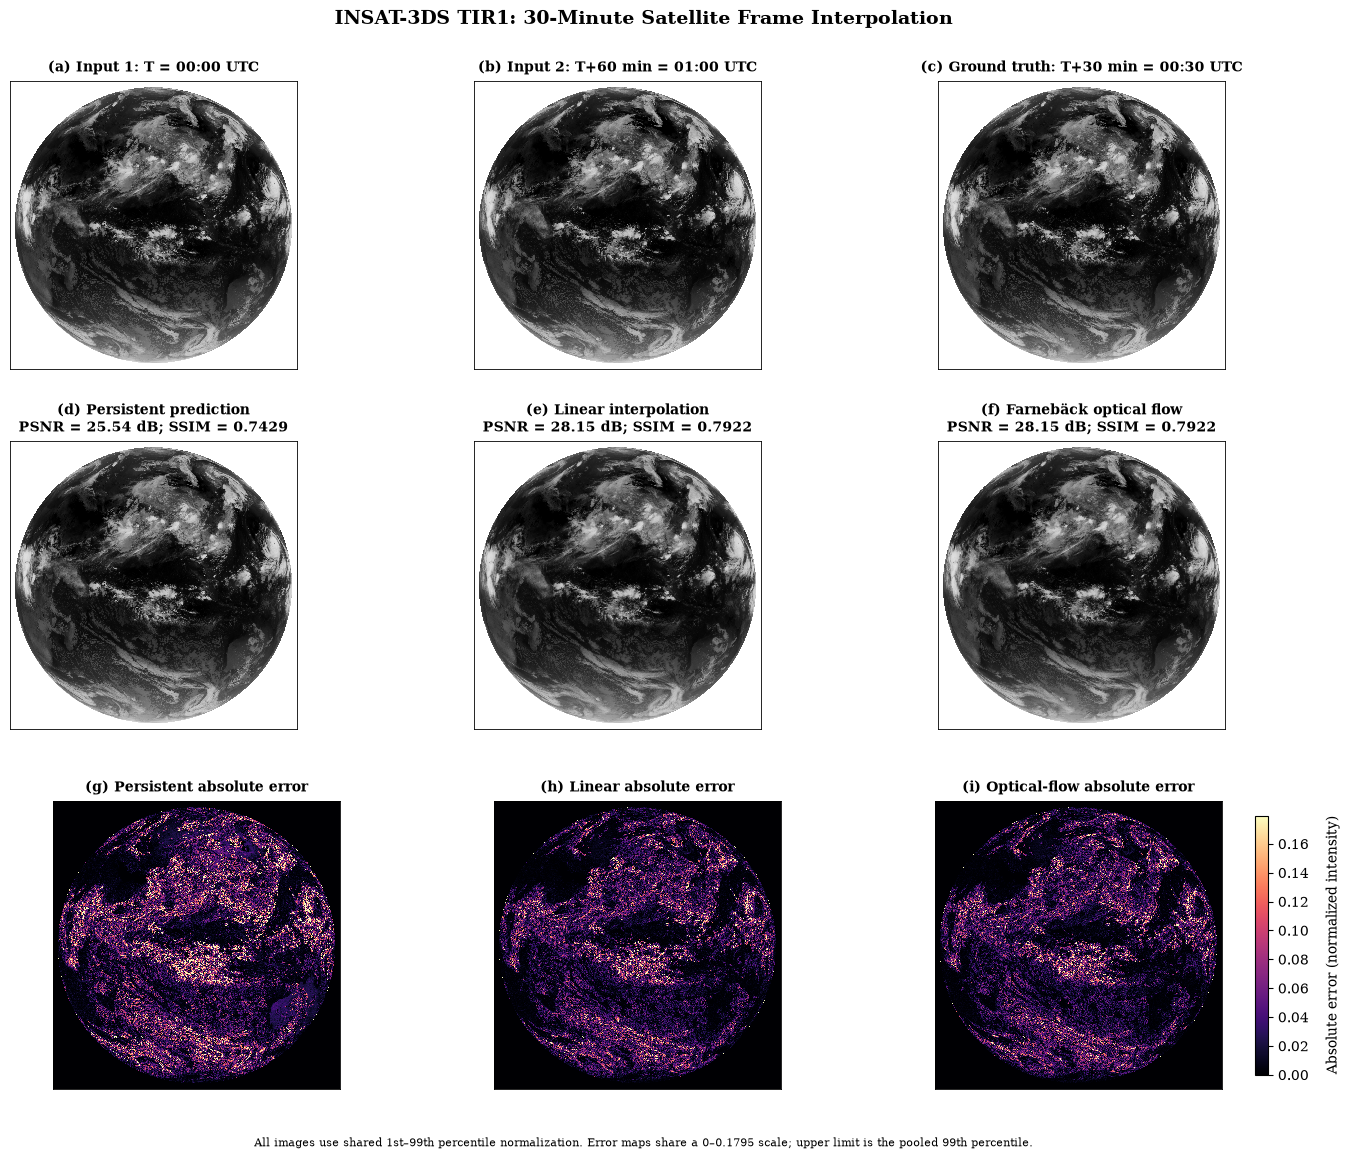


Publication figures saved:
PNG: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/INSAT3DS_BASELINES_FULL_IMAGE_30MIN/visualizations/triplet_00001_20260707_0000_publication_error_maps.png
PDF: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/INSAT3DS_BASELINES_FULL_IMAGE_30MIN/visualizations/triplet_00001_20260707_0000_publication_error_maps.pdf

Quantitative metrics for this triplet:


,Method,MSE,PSNR,SSIM,MAE,RMSE,FSIM
0,Persistent,0.002792,25.541552,0.742924,0.026574,0.052835,0.96755
1,Linear,0.001532,28.146549,0.792211,0.019422,0.039145,0.98892
2,OpticalFlow,0.001532,28.146549,0.792211,0.019422,0.039145,0.98892


In [11]:
# ================================================================
# INSAT-3DS 30-MINUTE INTERPOLATION
# PUBLICATION-STYLE FIGURE + ABSOLUTE ERROR MAPS
#
# Row 1: Input 1, Input 2, Ground Truth
# Row 2: Persistent, Linear, Farneback Optical Flow predictions
# Row 3: Absolute-error maps for the three methods
#
# Outputs:
#   1. PNG (600 DPI)
#   2. PDF (vector layout; image panels remain raster)
#
# ================================================================

from pathlib import Path
from datetime import datetime, timedelta
import re
import warnings

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

warnings.filterwarnings("ignore")

# ================================================================
# 1. CONFIGURATION
# ================================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

DATASET_DIR = PROJECT_DIR / "Dataset"

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "INSAT3DS_BASELINES_FULL_IMAGE_30MIN"
)

PREDICTION_DIR = OUTPUT_DIR / "predictions"

METRICS_CSV = (
    OUTPUT_DIR
    / "metrics"
    / "per_triplet_metrics.csv"
)

FIGURE_DIR = OUTPUT_DIR / "visualizations"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_DATASET_KEY = "IMG_TIR1"

# Select a successfully evaluated triplet.
TRIPLET_NUMBER = 1

# None = full satellite disk.
# Example: (500, 1500, 500, 1500)
# Format: (y_start, y_end, x_start, x_end)
CROP = None

# Error color scale:
# 99th percentile is robust to a few extreme error pixels.
# The same scale is used for all three error maps.
ERROR_PERCENTILE = 99.0

# Publication export settings
PNG_DPI = 600

# ================================================================
# 2. CHECK INPUT FILES
# ================================================================

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_DIR}"
    )

if not METRICS_CSV.exists():
    raise FileNotFoundError(
        f"Metrics file not found: {METRICS_CSV}"
    )

metrics_df = pd.read_csv(METRICS_CSV)

required_columns = {
    "Triplet_ID", "Method", "MSE", "PSNR", "SSIM"
}

missing_columns = required_columns - set(metrics_df.columns)

if missing_columns:
    raise ValueError(
        f"Metrics CSV missing columns: {missing_columns}"
    )

successful_ids = (
    metrics_df["Triplet_ID"]
    .drop_duplicates()
    .tolist()
)

if not 1 <= TRIPLET_NUMBER <= len(successful_ids):
    raise ValueError(
        f"TRIPLET_NUMBER must be from 1 to {len(successful_ids)}."
    )

triplet_id = successful_ids[TRIPLET_NUMBER - 1]

print("Selected triplet:", triplet_id)

# ================================================================
# 3. FIND THE ORIGINAL THREE FRAMES
# ================================================================

def extract_timestamp(path):
    match = re.search(
        r"(\d{2}[A-Z]{3}\d{4})_(\d{4})",
        path.name.upper()
    )

    if match is None:
        return None

    try:
        return datetime.strptime(
            match.group(1) + "_" + match.group(2),
            "%d%b%Y_%H%M"
        )
    except ValueError:
        return None


match = re.search(
    r"triplet_\d+_(\d{8}_\d{4})",
    triplet_id
)

if match is None:
    raise ValueError(
        f"Cannot parse timestamp from {triplet_id}"
    )

time_0 = datetime.strptime(
    match.group(1),
    "%Y%m%d_%H%M"
)

time_gt = time_0 + timedelta(minutes=30)
time_2 = time_0 + timedelta(minutes=60)

hdf5_files = []

for pattern in ("*.h5", "*.hdf5", "*.H5", "*.HDF5"):
    hdf5_files.extend(DATASET_DIR.rglob(pattern))

timestamp_map = {}

for path in sorted(set(hdf5_files)):
    timestamp = extract_timestamp(path)

    if timestamp is not None:
        timestamp_map.setdefault(timestamp, path)

for timestamp in (time_0, time_gt, time_2):
    if timestamp not in timestamp_map:
        raise FileNotFoundError(
            f"Original HDF5 frame not found for {timestamp}"
        )

file_input_1 = timestamp_map[time_0]
file_gt = timestamp_map[time_gt]
file_input_2 = timestamp_map[time_2]

print("Input 1:", file_input_1.name)
print("GT     :", file_gt.name)
print("Input 2:", file_input_2.name)

# ================================================================
# 4. LOAD ORIGINAL IMAGES
# ================================================================

def read_image(path):
    with h5py.File(path, "r") as f:
        if IMAGE_DATASET_KEY not in f:
            raise KeyError(
                f"{IMAGE_DATASET_KEY} not found in {path.name}"
            )
        image = np.asarray(f[IMAGE_DATASET_KEY][()])

    image = np.squeeze(image)

    if image.ndim != 2:
        raise ValueError(
            f"Expected a 2D image, received {image.shape}"
        )

    return image.astype(np.float32)


input_1_raw = read_image(file_input_1)
gt_raw = read_image(file_gt)
input_2_raw = read_image(file_input_2)

if not (
    input_1_raw.shape == gt_raw.shape == input_2_raw.shape
):
    raise ValueError("The original frames have different shapes.")

# ================================================================
# 5. CONSISTENT NORMALIZATION
# ================================================================

all_valid = np.concatenate([
    input_1_raw[np.isfinite(input_1_raw)],
    gt_raw[np.isfinite(gt_raw)],
    input_2_raw[np.isfinite(input_2_raw)]
])

norm_low = float(np.percentile(all_valid, 1))
norm_high = float(np.percentile(all_valid, 99))

if norm_high <= norm_low:
    raise ValueError("Invalid normalization range.")


def normalize_image(image):
    result = (
        (image - norm_low) / (norm_high - norm_low)
    )

    result = np.clip(result, 0, 1).astype(np.float32)
    result[~np.isfinite(image)] = np.nan

    return result


input_1 = normalize_image(input_1_raw)
gt = normalize_image(gt_raw)
input_2 = normalize_image(input_2_raw)

# Common valid region across all three original frames.
valid_mask = (
    np.isfinite(input_1)
    & np.isfinite(gt)
    & np.isfinite(input_2)
)

# ================================================================
# 6. LOAD THE SAVED PREDICTIONS
# ================================================================

def load_prediction(method):
    path = (
        PREDICTION_DIR
        / method
        / f"{triplet_id}_prediction.npy"
    )

    if not path.exists():
        raise FileNotFoundError(
            f"Prediction file not found: {path}"
        )

    prediction = np.load(path).astype(np.float32)

    if prediction.shape != gt.shape:
        raise ValueError(
            f"{method} shape {prediction.shape} != GT shape {gt.shape}"
        )

    return prediction


predictions = {
    "Persistent": load_prediction("Persistent"),
    "Linear": load_prediction("Linear"),
    "Farneback Optical Flow": load_prediction("OpticalFlow"),
}

# ================================================================
# 7. COMPUTE ABSOLUTE ERROR MAPS
# ================================================================

error_maps = {}

for method, prediction in predictions.items():

    method_valid = (
        valid_mask
        & np.isfinite(prediction)
    )

    error = np.full(
        gt.shape,
        np.nan,
        dtype=np.float32
    )

    error[method_valid] = np.abs(
        prediction[method_valid] - gt[method_valid]
    )

    error_maps[method] = error


# Determine one common error scale for all methods.
all_errors = np.concatenate([
    error[np.isfinite(error)]
    for error in error_maps.values()
    if np.any(np.isfinite(error))
])

if all_errors.size == 0:
    raise ValueError("No valid pixels available for error maps.")

error_vmax = float(
    np.percentile(all_errors, ERROR_PERCENTILE)
)

error_vmax = max(error_vmax, 1e-6)

print(f"Shared error-map scale: 0 to {error_vmax:.6f}")
print(
    f"Values above the {ERROR_PERCENTILE:g}th percentile "
    "will be saturated at the upper color limit."
)

# ================================================================
# 8. OPTIONAL CROP
# ================================================================

def apply_crop(image):
    if CROP is None:
        return image

    y1, y2, x1, x2 = CROP

    if not (
        0 <= y1 < y2 <= image.shape[0]
        and 0 <= x1 < x2 <= image.shape[1]
    ):
        raise ValueError(
            f"Crop {CROP} is outside image shape {image.shape}"
        )

    return image[y1:y2, x1:x2]


input_1 = apply_crop(input_1)
input_2 = apply_crop(input_2)
gt = apply_crop(gt)

predictions = {
    name: apply_crop(image)
    for name, image in predictions.items()
}

error_maps = {
    name: apply_crop(image)
    for name, image in error_maps.items()
}

# ================================================================
# 9. EXTRACT METRICS FOR TITLES
# ================================================================

def get_metric(method, column):
    if method == "Farneback Optical Flow":
        lookup_method = "OpticalFlow"
    else:
        lookup_method = method

    row = metrics_df[
        (metrics_df["Triplet_ID"] == triplet_id)
        & (metrics_df["Method"] == lookup_method)
    ]

    if row.empty:
        return None

    value = row.iloc[0][column]

    if pd.isna(value):
        return None

    return float(value)


# ================================================================
# 10. CREATE PUBLICATION-STYLE FIGURE
# ================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "figure.titlesize": 14,
    "savefig.facecolor": "white",
})

fig = plt.figure(
    figsize=(15, 12),
    facecolor="white"
)

gs = GridSpec(
    3,
    3,
    figure=fig,
    height_ratios=[1, 1, 1],
    hspace=0.25,
    wspace=0.12,
    left=0.035,
    right=0.93,
    top=0.91,
    bottom=0.07
)

# Row 1: input frames and GT.
top_images = [
    input_1,
    input_2,
    gt,
]

top_titles = [
    f"(a) Input 1: T = {time_0:%H:%M} UTC",
    f"(b) Input 2: T+60 min = {time_2:%H:%M} UTC",
    f"(c) Ground truth: T+30 min = {time_gt:%H:%M} UTC",
]

for col, (image, title) in enumerate(zip(top_images, top_titles)):

    ax = fig.add_subplot(gs[0, col])

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(title, pad=7, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_linewidth(0.6)


# Row 2: predictions.
prediction_order = [
    "Persistent",
    "Linear",
    "Farneback Optical Flow",
]

prediction_labels = [
    "(d) Persistent prediction",
    "(e) Linear interpolation",
    "(f) Farnebäck optical flow",
]

for col, (method, label) in enumerate(
    zip(prediction_order, prediction_labels)
):

    ax = fig.add_subplot(gs[1, col])

    ax.imshow(
        predictions[method],
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    psnr = get_metric(method, "PSNR")
    ssim = get_metric(method, "SSIM")

    metric_text = ""

    if psnr is not None and ssim is not None:
        metric_text = f"\nPSNR = {psnr:.2f} dB; SSIM = {ssim:.4f}"

    ax.set_title(
        label + metric_text,
        pad=7,
        fontweight="bold"
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_linewidth(0.6)


# Row 3: absolute-error maps.
error_labels = [
    "(g) Persistent absolute error",
    "(h) Linear absolute error",
    "(i) Optical-flow absolute error",
]

error_image_handles = []

for col, (method, label) in enumerate(
    zip(prediction_order, error_labels)
):

    ax = fig.add_subplot(gs[2, col])

    error = error_maps[method]

    im = ax.imshow(
        error,
        cmap="magma",
        vmin=0,
        vmax=error_vmax,
        interpolation="nearest"
    )

    error_image_handles.append(im)

    ax.set_title(label, pad=7, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_linewidth(0.6)


# Shared color bar for all error maps.
cbar = fig.colorbar(
    error_image_handles[0],
    ax=[
        fig.axes[-3],
        fig.axes[-2],
        fig.axes[-1],
    ],
    location="right",
    fraction=0.025,
    pad=0.025,
    shrink=0.9
)

cbar.set_label(
    "Absolute error (normalized intensity)",
    rotation=90,
    labelpad=12
)

fig.suptitle(
    "INSAT-3DS TIR1: 30-Minute Satellite Frame Interpolation",
    fontweight="bold",
    y=0.97
)

# Add a small normalization note.
fig.text(
    0.5,
    0.025,
    (
        "All images use shared 1st–99th percentile normalization. "
        f"Error maps share a 0–{error_vmax:.4f} scale; "
        f"upper limit is the pooled {ERROR_PERCENTILE:g}th percentile."
    ),
    ha="center",
    va="center",
    fontsize=8
)

# ================================================================
# 11. SAVE HIGH-RESOLUTION OUTPUTS
# ================================================================

png_path = (
    FIGURE_DIR
    / f"{triplet_id}_publication_error_maps.png"
)

pdf_path = (
    FIGURE_DIR
    / f"{triplet_id}_publication_error_maps.pdf"
)

fig.savefig(
    png_path,
    dpi=PNG_DPI,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nPublication figures saved:")
print("PNG:", png_path)
print("PDF:", pdf_path)

# ================================================================
# 12. PRINT METRICS TABLE FOR THE SELECTED TRIPLET
# ================================================================

selected = metrics_df[
    metrics_df["Triplet_ID"] == triplet_id
].copy()

columns_to_show = [
    col for col in
    ["Method", "MSE", "PSNR", "SSIM", "MAE", "RMSE", "FSIM"]
    if col in selected.columns
]

print("\nQuantitative metrics for this triplet:")
display(selected[columns_to_show].round(6))

In [2]:
# =====================================================================
# INSAT-3DS FULL-IMAGE FRAME INTERPOLATION — 30-MINUTE GT
#
# Input 0 : T
# Ground truth: T + 30 minutes
# Input 2 : T + 60 minutes
#
# Methods:
#   1. Persistent
#   2. Linear interpolation
#   3. Farneback optical flow
#   4. SuperSloMo
#   5. RIFE
#
# Full original resolution only.
# No resizing. No patches. No tiling.
#
# Metrics: MSE, PSNR, SSIM, MAE, RMSE, FSIM
# =====================================================================

import os
import re
import sys
import time
import warnings
import importlib.util
import traceback

from pathlib import Path
from datetime import datetime, timedelta

import cv2
import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import piq

from skimage.metrics import structural_similarity

warnings.filterwarnings("ignore")

# =====================================================================
# 1. PATHS AND SETTINGS
# =====================================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

DATASET_DIR = PROJECT_DIR / "Dataset"

RIFE_DIR = PROJECT_DIR / "Official_RIFE"
RIFE_MODEL_DIR = RIFE_DIR / "model"
RIFE_CHECKPOINT = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048" / "epoch_100.pth"
)

SUPERSLOMO_DIR = PROJECT_DIR / "SuperSloMo"
SUPERSLOMO_SOURCE = SUPERSLOMO_DIR / "model.py"
SUPERSLOMO_CHECKPOINT = (
    PROJECT_DIR / "checkpoints_NEW" / "SuperSloMo_2048" / "epoch_100.pth"
)

OUTPUT_DIR = (
    PROJECT_DIR / "results" / "INSAT3DS_FULL_IMAGE_30MIN_ALL_METHODS"
)
PREDICTION_DIR = OUTPUT_DIR / "predictions"
METRICS_DIR = OUTPUT_DIR / "metrics"
COMPARISON_DIR = OUTPUT_DIR / "comparisons"

IMAGE_DATASET_KEY = "IMG_TIR1"
FRAME_INTERVAL_MINUTES = 30

# Set to an integer such as 2 for a quick test; None means all triplets.
MAX_TRIPLETS = None

LOWER_PERCENTILE = 1.0
UPPER_PERCENTILE = 99.0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Keep False unless you have confirmed that the RIFE model expects
# replicated RGB input for your particular repository implementation.
RIFE_USE_RGB = True

FLOW_PARAMS = {
    "pyr_scale": 0.5,
    "levels": 4,
    "winsize": 21,
    "iterations": 5,
    "poly_n": 7,
    "poly_sigma": 1.5,
    "flags": 0,
}

for directory in [
    OUTPUT_DIR, PREDICTION_DIR, METRICS_DIR, COMPARISON_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

METHODS = [
    "Persistent",
    "Linear",
    "OpticalFlow",
    "SuperSloMo",
    "RIFE",
]

for method in METHODS:
    (PREDICTION_DIR / method).mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("INSAT-3DS FULL-IMAGE INTERPOLATION EVALUATION")
print("=" * 80)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATASET_DIR)
print("Output:", OUTPUT_DIR)
print("RIFE checkpoint:", RIFE_CHECKPOINT)
print("SuperSloMo checkpoint:", SUPERSLOMO_CHECKPOINT)
print("Resize: NO")
print("Patches: NO")
print("=" * 80)

# =====================================================================
# 2. FIND FILES AND TIMESTAMPS
# =====================================================================

def find_hdf5_files(root):
    if not root.exists():
        raise FileNotFoundError(
            f"Dataset folder does not exist: {root}\n"
            "Change DATASET_DIR to the directory containing your INSAT HDF5 files."
        )

    found = []
    for pattern in ("*.h5", "*.hdf5", "*.H5", "*.HDF5"):
        found.extend(root.rglob(pattern))

    return sorted(set(found))


def extract_timestamp(path):
    match = re.search(
        r"(\d{2}[A-Z]{3}\d{4})_(\d{4})",
        path.name.upper()
    )
    if not match:
        return None

    try:
        return datetime.strptime(
            f"{match.group(1)}_{match.group(2)}",
            "%d%b%Y_%H%M"
        )
    except ValueError:
        return None


def build_triplets(files):
    timestamp_to_file = {}

    for path in files:
        timestamp = extract_timestamp(path)
        if timestamp is not None:
            timestamp_to_file.setdefault(timestamp, path)

    times = sorted(timestamp_to_file)
    interval = timedelta(minutes=FRAME_INTERVAL_MINUTES)
    triplets = []

    for t0 in times:
        t1 = t0 + interval
        t2 = t0 + interval * 2

        if t1 in timestamp_to_file and t2 in timestamp_to_file:
            triplets.append({
                "time_0": t0,
                "time_1": t1,
                "time_2": t2,
                "file_0": timestamp_to_file[t0],
                "file_1": timestamp_to_file[t1],
                "file_2": timestamp_to_file[t2],
            })

    if MAX_TRIPLETS is not None:
        triplets = triplets[:MAX_TRIPLETS]

    return triplets


def read_hdf5_image(path):
    with h5py.File(path, "r") as hf:
        if IMAGE_DATASET_KEY not in hf:
            raise KeyError(
                f"{IMAGE_DATASET_KEY} not found in {path.name}"
            )
        image = np.asarray(hf[IMAGE_DATASET_KEY][()])

    image = np.squeeze(image)

    if image.ndim != 2:
        raise ValueError(
            f"Expected a 2D image; got {image.shape} in {path.name}"
        )

    return image.astype(np.float32)


# =====================================================================
# 3. NORMALIZATION
# =====================================================================

def normalize_triplet(image0, gt, image2):
    finite_parts = [
        image[np.isfinite(image)]
        for image in (image0, gt, image2)
    ]

    finite_parts = [a for a in finite_parts if a.size > 0]
    if len(finite_parts) != 3:
        raise ValueError("One or more frames contain no valid pixels.")

    all_values = np.concatenate(finite_parts)

    low = float(np.percentile(all_values, LOWER_PERCENTILE))
    high = float(np.percentile(all_values, UPPER_PERCENTILE))

    if not np.isfinite(low + high) or high <= low:
        raise ValueError(f"Invalid normalization range: {low}, {high}")

    normalized = []
    for image in (image0, gt, image2):
        out = (image - low) / (high - low)
        out = np.clip(out, 0, 1).astype(np.float32)
        out[~np.isfinite(image)] = np.nan
        normalized.append(out)

    image0n, gtn, image2n = normalized
    valid = (
        np.isfinite(image0n)
        & np.isfinite(gtn)
        & np.isfinite(image2n)
    )

    if not valid.any():
        raise ValueError("No pixels are valid in all three frames.")

    return image0n, gtn, image2n, valid, low, high


def safe_image(image):
    return np.clip(
        np.nan_to_num(image, nan=0.0, posinf=0.0, neginf=0.0),
        0.0, 1.0
    ).astype(np.float32)


# =====================================================================
# 4. BASELINE METHODS
# =====================================================================

def predict_persistent(image0, image2):
    return safe_image(image0)


def predict_linear(image0, image2):
    return safe_image(0.5 * safe_image(image0) + 0.5 * safe_image(image2))


def predict_optical_flow(image0, image2):
    a = safe_image(image0)
    b = safe_image(image2)

    flow_forward = cv2.calcOpticalFlowFarneback(
        a, b, None, **FLOW_PARAMS
    )
    flow_backward = cv2.calcOpticalFlowFarneback(
        b, a, None, **FLOW_PARAMS
    )

    h, w = a.shape
    grid_x, grid_y = np.meshgrid(
        np.arange(w, dtype=np.float32),
        np.arange(h, dtype=np.float32)
    )

    warped_a = cv2.remap(
        a,
        grid_x - 0.5 * flow_forward[..., 0],
        grid_y - 0.5 * flow_forward[..., 1],
        cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    warped_b = cv2.remap(
        b,
        grid_x - 0.5 * flow_backward[..., 0],
        grid_y - 0.5 * flow_backward[..., 1],
        cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    return safe_image(0.5 * (warped_a + warped_b))


# =====================================================================
# 5. LOAD SUPERSLOMO
# =====================================================================

superslomo_model = None
superslomo_error = None

def extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):
        for key in (
            "state_dict", "model_state_dict", "model",
            "network", "net", "flownet"
        ):
            value = checkpoint.get(key)
            if isinstance(value, dict) and value:
                if any(torch.is_tensor(v) for v in value.values()):
                    return value

        if any(torch.is_tensor(v) for v in checkpoint.values()):
            return checkpoint

    raise ValueError("Could not identify model weights in checkpoint.")


try:
    if not SUPERSLOMO_SOURCE.exists():
        raise FileNotFoundError(f"Missing model source: {SUPERSLOMO_SOURCE}")
    if not SUPERSLOMO_CHECKPOINT.exists():
        raise FileNotFoundError(f"Missing checkpoint: {SUPERSLOMO_CHECKPOINT}")

    sys.path.insert(0, str(SUPERSLOMO_DIR))

    # Import the local model.py directly to avoid collision with RIFE's model package.
    spec = importlib.util.spec_from_file_location(
        "insat_superslomo_module", str(SUPERSLOMO_SOURCE)
    )
    ss_module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(ss_module)

    # Find a model class defined in this file.
    candidate_classes = [
        getattr(ss_module, name, None)
        for name in ("SuperSloMo", "Model", "Network", "FlowNet")
    ]
    candidate_classes = [
        c for c in candidate_classes if isinstance(c, type)
    ]

    if not candidate_classes:
        raise AttributeError(
            "No recognized model class found in SuperSloMo/model.py. "
            "Check the class name in your model file."
        )

    # Prefer a class named SuperSloMo, otherwise use the first candidate.
    ModelClass = getattr(ss_module, "SuperSloMo", candidate_classes[0])
    superslomo_model = ModelClass()

    checkpoint = torch.load(
        SUPERSLOMO_CHECKPOINT,
        map_location="cpu",
        weights_only=False
    )
    weights = extract_state_dict(checkpoint)

    # Try the common wrapper keys; report mismatch if architecture differs.
    try:
        superslomo_model.load_state_dict(weights, strict=True)
    except RuntimeError:
        # Some training checkpoints wrap weights with module. prefix.
        weights = {
            k.removeprefix("module."): v
            for k, v in weights.items()
            if torch.is_tensor(v)
        }
        superslomo_model.load_state_dict(weights, strict=True)

    superslomo_model = superslomo_model.to(DEVICE).eval()
    print("SuperSloMo: loaded successfully.")

except Exception as e:
    superslomo_model = None
    superslomo_error = f"{type(e).__name__}: {e}"
    print("SuperSloMo LOAD FAILED:", superslomo_error)


def predict_superslomo(image0, image2):
    if superslomo_model is None:
        raise RuntimeError(f"SuperSloMo unavailable: {superslomo_error}")

    # This implementation expects grayscale [B,1,H,W].
    a = torch.from_numpy(safe_image(image0))[None, None].to(DEVICE)
    b = torch.from_numpy(safe_image(image2))[None, None].to(DEVICE)

    # Pad only for model compatibility; no resizing and no patches.
    h, w = a.shape[-2:]
    ph = (32 - h % 32) % 32
    pw = (32 - w % 32) % 32

    a_pad = F.pad(a, (0, pw, 0, ph), mode="replicate")
    b_pad = F.pad(b, (0, pw, 0, ph), mode="replicate")

    with torch.inference_mode():
        # The common SuperSloMo model.py API used in this project:
        # model(frame0, frame1, t=0.5)
        output = superslomo_model(a_pad, b_pad, t=0.5)

    if isinstance(output, (tuple, list)):
        output = output[0]

    output = output[..., :h, :w]
    prediction = output[0, 0].detach().float().cpu().numpy()

    if prediction.shape != (h, w):
        raise ValueError(f"SuperSloMo returned {prediction.shape}; expected {(h,w)}")

    return safe_image(prediction)


# =====================================================================
# 6. LOAD RIFE
# =====================================================================

rife_model = None
rife_error = None

try:
    if not (RIFE_MODEL_DIR / "RIFE.py").exists():
        raise FileNotFoundError(f"Missing RIFE source: {RIFE_MODEL_DIR / 'RIFE.py'}")
    if not RIFE_CHECKPOINT.exists():
        raise FileNotFoundError(f"Missing RIFE checkpoint: {RIFE_CHECKPOINT}")

    # Prevent the SuperSloMo model.py from shadowing RIFE's model package.
    sys.modules.pop("model.RIFE", None)
    sys.modules.pop("model.IFNet", None)
    sys.modules.pop("model", None)

    sys.path[:] = [
        p for p in sys.path
        if Path(p).resolve() != SUPERSLOMO_DIR.resolve()
    ]
    sys.path.insert(0, str(RIFE_DIR))

    rife_spec = importlib.util.spec_from_file_location(
        "insat_rife_module",
        str(RIFE_MODEL_DIR / "RIFE.py")
    )
    rife_module = importlib.util.module_from_spec(rife_spec)

    # RIFE implementations sometimes import model.IFNet. Make the RIFE
    # directory importable before executing the source file.
    if str(RIFE_DIR) not in sys.path:
        sys.path.insert(0, str(RIFE_DIR))

    rife_spec.loader.exec_module(rife_module)
    RIFEModel = getattr(rife_module, "Model")
    rife_model = RIFEModel()

    if hasattr(rife_model, "device"):
        try:
            rife_model.device()
        except Exception:
            pass

    checkpoint = torch.load(
        RIFE_CHECKPOINT,
        map_location="cpu",
        weights_only=False
    )
    weights = extract_state_dict(checkpoint)
    weights = {
        k.removeprefix("module."): v
        for k, v in weights.items()
        if torch.is_tensor(v)
    }

    if not hasattr(rife_model, "flownet"):
        raise AttributeError(
            "This RIFE Model has no .flownet attribute. "
            "Its checkpoint-loading API is different."
        )

    rife_model.flownet.load_state_dict(weights, strict=True)

    if hasattr(rife_model, "flownet"):
        rife_model.flownet.to(DEVICE).eval()

    print("RIFE: loaded successfully.")

except Exception as e:
    rife_model = None
    rife_error = f"{type(e).__name__}: {e}"
    print("RIFE LOAD FAILED:", rife_error)


def predict_rife(image0, image2):
    if rife_model is None:
        raise RuntimeError(f"RIFE unavailable: {rife_error}")

    a_np = safe_image(image0)
    b_np = safe_image(image2)

    h, w = a_np.shape

    a = torch.from_numpy(a_np)[None, None].to(DEVICE)
    b = torch.from_numpy(b_np)[None, None].to(DEVICE)

    if RIFE_USE_RGB:
        a = a.repeat(1, 3, 1, 1)
        b = b.repeat(1, 3, 1, 1)

    # Full-frame inference. Pad dimensions to multiples of 32.
    # No resizing and no patches.
    padded_h = ((h + 31) // 32) * 32
    padded_w = ((w + 31) // 32) * 32
    pad_bottom = padded_h - h
    pad_right = padded_w - w

    a = F.pad(a, (0, pad_right, 0, pad_bottom), mode="replicate")
    b = F.pad(b, (0, pad_right, 0, pad_bottom), mode="replicate")

    with torch.inference_mode():
        # Official RIFE Model API.
        prediction = rife_model.inference(a, b, scale=1.0)

    if isinstance(prediction, (tuple, list)):
        prediction = prediction[0]

    # Crop prediction back to original INSAT image size.
    prediction = prediction[..., :h, :w]

    if prediction.ndim != 4:
        raise ValueError(f"Unexpected RIFE output shape: {tuple(prediction.shape)}")

    # If output has 3 channels, average them to grayscale.
    if prediction.shape[1] == 3:
        prediction = prediction.mean(dim=1, keepdim=True)
    elif prediction.shape[1] != 1:
        raise ValueError(
            f"RIFE output has unexpected channel count: {prediction.shape[1]}"
        )

    prediction = prediction[0, 0].detach().float().cpu().numpy()

    if prediction.shape != (h, w):
        raise ValueError(
            f"RIFE output shape {prediction.shape}; expected {(h, w)}"
        )

    return safe_image(prediction)


# =====================================================================
# 7. METRICS
# =====================================================================

def calculate_metrics(prediction, target, valid_mask):
    prediction = np.asarray(prediction, dtype=np.float32)
    target = np.asarray(target, dtype=np.float32)

    if prediction.shape != target.shape:
        raise ValueError(
            f"Metric shape mismatch: prediction={prediction.shape}, "
            f"target={target.shape}"
        )

    mask = (
        valid_mask
        & np.isfinite(prediction)
        & np.isfinite(target)
    )

    if not mask.any():
        raise ValueError("No valid pixels for metrics.")

    diff = (
        prediction[mask].astype(np.float64)
        - target[mask].astype(np.float64)
    )

    mse = float(np.mean(diff ** 2))
    mae = float(np.mean(np.abs(diff)))
    rmse = float(np.sqrt(mse))
    psnr = float("inf") if mse == 0 else float(10 * np.log10(1.0 / mse))

    pred_safe = safe_image(prediction)
    target_safe = safe_image(target)

    ssim = float(structural_similarity(
        target_safe,
        pred_safe,
        data_range=1.0,
        gaussian_weights=True,
        sigma=1.5,
        use_sample_covariance=False
    ))

    pred_tensor = torch.from_numpy(
        np.ascontiguousarray(pred_safe)
    )[None, None].to(DEVICE)

    target_tensor = torch.from_numpy(
        np.ascontiguousarray(target_safe)
    )[None, None].to(DEVICE)

    with torch.inference_mode():
        fsim = float(piq.fsim(
            pred_tensor,
            target_tensor,
            data_range=1.0,
            chromatic=False,
            reduction="mean"
        ).item())

    return {
        "MSE": mse,
        "PSNR": psnr,
        "SSIM": ssim,
        "MAE": mae,
        "RMSE": rmse,
        "FSIM": fsim,
        "Valid_Pixels": int(mask.sum()),
    }


# =====================================================================
# 8. SAVE OUTPUTS
# =====================================================================

def save_prediction(prediction, method, triplet_id):
    method_dir = PREDICTION_DIR / method
    method_dir.mkdir(parents=True, exist_ok=True)

    prediction = safe_image(prediction)

    # Float array preserves normalized full-resolution prediction.
    np.save(
        method_dir / f"{triplet_id}.npy",
        prediction.astype(np.float32)
    )

    # PNG is an 8-bit visualization only; use NPY for numeric evaluation.
    cv2.imwrite(
        str(method_dir / f"{triplet_id}.png"),
        np.round(prediction * 255).astype(np.uint8)
    )


def save_comparison(triplet_id, image0, gt, image2, predictions):
    names = ["Input T", "Ground Truth T+30", "Input T+60"] + list(predictions.keys())
    images = [safe_image(image0), safe_image(gt), safe_image(image2)]
    images.extend(safe_image(p) for p in predictions.values())

    # Full-resolution montage, without resizing individual images.
    # Each row is saved as a separate original-size panel.
    out_dir = COMPARISON_DIR / triplet_id
    out_dir.mkdir(parents=True, exist_ok=True)

    for name, image in zip(names, images):
        safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", name)
        cv2.imwrite(
            str(out_dir / f"{safe_name}.png"),
            np.round(image * 255).astype(np.uint8)
        )


# =====================================================================
# 9. MAIN EVALUATION
# =====================================================================

hdf5_files = find_hdf5_files(DATASET_DIR)
print("\nHDF5 files found:", len(hdf5_files))

if not hdf5_files:
    raise RuntimeError(
        f"No HDF5 files found under {DATASET_DIR}. Check DATASET_DIR."
    )

triplets = build_triplets(hdf5_files)
print("30-minute triplets found:", len(triplets))

if not triplets:
    raise RuntimeError(
        "No T, T+30, T+60 triplets found. Check filename timestamps "
        "and whether the data contain frames at 30-minute intervals."
    )

all_results = []
failed_results = []
start_time = time.time()

for idx, triplet in enumerate(triplets, start=1):
    t0 = triplet["time_0"]
    t1 = triplet["time_1"]
    t2 = triplet["time_2"]

    triplet_id = f"triplet_{idx:05d}_{t0.strftime('%Y%m%d_%H%M')}"

    print("\n" + "=" * 90)
    print(f"[{idx}/{len(triplets)}] {triplet_id}")
    print("Input 1     :", t0)
    print("Ground truth:", t1)
    print("Input 2     :", t2)

    try:
        raw0 = read_hdf5_image(triplet["file_0"])
        raw_gt = read_hdf5_image(triplet["file_1"])
        raw2 = read_hdf5_image(triplet["file_2"])

        if not (raw0.shape == raw_gt.shape == raw2.shape):
            raise ValueError(
                f"Original image shape mismatch: {raw0.shape}, "
                f"{raw_gt.shape}, {raw2.shape}"
            )

        image0, gt, image2, valid_mask, norm_low, norm_high = (
            normalize_triplet(raw0, raw_gt, raw2)
        )

        original_shape = tuple(gt.shape)
        print("Original image shape:", original_shape)
        print("Valid pixels:", int(valid_mask.sum()))
        print(f"Normalization limits: {norm_low:.6f} to {norm_high:.6f}")

        # Baseline predictions.
        predictions = {}

        baseline_functions = {
            "Persistent": predict_persistent,
            "Linear": predict_linear,
            "OpticalFlow": predict_optical_flow,
        }

        for method, function in baseline_functions.items():
            try:
                predictions[method] = function(image0, image2)
            except Exception as e:
                print(f"{method} FAILED: {type(e).__name__}: {e}")
                failed_results.append({
                    "Triplet_ID": triplet_id,
                    "Method": method,
                    "Error": repr(e)
                })

        # Deep models: errors are recorded separately so one failed model
        # does not stop the remaining methods.
        deep_functions = {
            "SuperSloMo": predict_superslomo,
            "RIFE": predict_rife,
        }

        for method, function in deep_functions.items():
            try:
                pred = function(image0, image2)

                if pred.shape != original_shape:
                    raise ValueError(
                        f"{method} returned {pred.shape}; expected {original_shape}"
                    )

                predictions[method] = pred
                print(f"{method} prediction shape:", pred.shape)

            except Exception as e:
                print(f"{method} FAILED: {type(e).__name__}: {e}")
                traceback.print_exc(limit=2)

                failed_results.append({
                    "Triplet_ID": triplet_id,
                    "Method": method,
                    "Error": repr(e)
                })

        # Evaluate each successful prediction.
        for method, prediction in predictions.items():
            if prediction.shape != original_shape:
                raise ValueError(
                    f"{method} shape changed: {prediction.shape} vs {original_shape}"
                )

            metrics = calculate_metrics(
                prediction=prediction,
                target=gt,
                valid_mask=valid_mask
            )

            row = {
                "Triplet_ID": triplet_id,
                "Method": method,
                "Time_0": t0.isoformat(),
                "Ground_Truth_Time": t1.isoformat(),
                "Time_2": t2.isoformat(),
                "File_0": str(triplet["file_0"]),
                "Ground_Truth_File": str(triplet["file_1"]),
                "File_2": str(triplet["file_2"]),
                "Height": original_shape[0],
                "Width": original_shape[1],
                "Normalization_Low": norm_low,
                "Normalization_High": norm_high,
                **metrics
            }
            all_results.append(row)

            save_prediction(prediction, method, triplet_id)

            print(
                f"{method:12s} | "
                f"MSE={metrics['MSE']:.8f} | "
                f"PSNR={metrics['PSNR']:.4f} dB | "
                f"SSIM={metrics['SSIM']:.6f} | "
                f"MAE={metrics['MAE']:.6f} | "
                f"RMSE={metrics['RMSE']:.6f} | "
                f"FSIM={metrics['FSIM']:.6f}"
            )

        save_comparison(triplet_id, image0, gt, image2, predictions)

    except Exception as e:
        print("TRIPLET FAILED:", type(e).__name__, str(e))
        traceback.print_exc(limit=2)

        failed_results.append({
            "Triplet_ID": triplet_id,
            "Time_0": t0.isoformat(),
            "Ground_Truth_Time": t1.isoformat(),
            "Time_2": t2.isoformat(),
            "Error": repr(e)
        })

    # Save after every triplet so results survive kernel interruption.
    if all_results:
        pd.DataFrame(all_results).to_csv(
            METRICS_DIR / "per_triplet_metrics.csv",
            index=False
        )

    if failed_results:
        pd.DataFrame(failed_results).to_csv(
            METRICS_DIR / "failed_triplets.csv",
            index=False
        )

# =====================================================================
# 10. FINAL SUMMARY
# =====================================================================

if all_results:
    results_df = pd.DataFrame(all_results)

    per_triplet_path = METRICS_DIR / "per_triplet_metrics.csv"
    results_df.to_csv(per_triplet_path, index=False)

    metric_columns = ["MSE", "PSNR", "SSIM", "MAE", "RMSE", "FSIM"]
    summary_df = (
        results_df.groupby("Method")[metric_columns]
        .agg(["mean", "std", "median"])
    )
    summary_df.columns = [
        f"{metric}_{stat}" for metric, stat in summary_df.columns
    ]
    summary_df = summary_df.reset_index()

    summary_path = METRICS_DIR / "summary_metrics.csv"
    summary_df.to_csv(summary_path, index=False)

    print("\n" + "=" * 110)
    print("FINAL SUMMARY — FULL-IMAGE INSAT-3DS EVALUATION")
    print("=" * 110)
    print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
    print("\nPer-triplet CSV:", per_triplet_path)
    print("Summary CSV    :", summary_path)

    print("\nBest mean values:")
    for metric in metric_columns:
        means = results_df.groupby("Method")[metric].mean()
        if metric in ("MSE", "MAE", "RMSE"):
            method = means.idxmin()
            value = means.min()
            direction = "lower is better"
        else:
            method = means.idxmax()
            value = means.max()
            direction = "higher is better"

        print(f"{metric:6s}: {method:12s} {value:.6f} ({direction})")
else:
    print("No successful predictions were evaluated.")

if failed_results:
    failed_path = METRICS_DIR / "failed_triplets.csv"
    pd.DataFrame(failed_results).to_csv(failed_path, index=False)
    print("\nFailed methods/triplets:", failed_path)

print(f"\nTotal elapsed time: {(time.time() - start_time) / 60:.2f} minutes")
print("All outputs saved under:", OUTPUT_DIR)

INSAT-3DS FULL-IMAGE INTERPOLATION EVALUATION
Device: cuda
GPU: NVIDIA H200 NVL
Dataset: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset
Output: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/INSAT3DS_FULL_IMAGE_30MIN_ALL_METHODS
RIFE checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_100.pth
SuperSloMo checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_100.pth
Resize: NO
Patches: NO
SuperSloMo: loaded successfully.
RIFE: loaded successfully.

HDF5 files found: 426
30-minute triplets found: 416

[1/416] triplet_00001_20260707_0000
Input 1     : 2026-07-07 00:00:00
Ground truth: 2026-07-07 00:30:00
Input 2     : 2026-07-07 01:00:00
Original image shape: (2816, 2805)
Valid pixels: 7898880
Normalization limits: 505.000000 to 1023.000000
SuperSloMo prediction shape: (2816, 2805)
RIFE prediction shape: (2816, 2805)
Persistent   | MSE=0.00279155 | PSNR=25.5416